Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [2]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel
from Components.Controllers import LTI_LQRc_RHG
from Components.Solver import fbrs

In [4]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [59]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [60]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseModel(parameter_file, boundary_condition="Constant Head")

In [61]:
n_well = model.well_to_agent.shape[0]

In [62]:
# Define base pumping commands
T = 100
base_command = np.split(np.kron(np.eye(n_well), -np.ones((1,T))), T*np.linspace(1,n_well-1,n_well-1, dtype=int), axis=1)
# Other pumping parameters
max_intensity = 1000
n_steps_intensity = 10
intensity_step = max_intensity/n_steps_intensity

In [86]:
# Compute heads and costs for different commands at different wells
head = np.array([[np.hstack((system.get_heads_at_wells()[:,np.newaxis], np.zeros((n_well, T))))] * n_steps_intensity] * n_well)
cost = np.array([[np.zeros((model.n_agent, T))] * n_steps_intensity] * n_well)
for ii in range(n_well):
    for step in trange(n_steps_intensity):
        system.state = system.initial_state.copy()
        intensity = (step+1)*intensity_step
        for k in range(T):
            system.apply_command(intensity*base_command[ii][:, [k]])
            head[ii, step, :, k+1] = system.get_heads_at_wells()
            cost[ii, step, :, k] = system.compute_cost(intensity*base_command[ii][:, [k]]).flatten()

100%|██████████| 10/10 [01:13<00:00,  7.39s/it]


In [64]:
# Compute expected heads for those commands
B = sp.hstack(model.B_v)
system.state = system.initial_state.copy()
model_head = np.array([[np.hstack((model.translate_state(system.get_state()[0,:,:]), np.zeros((model.nx, T))))] * n_steps_intensity] * n_well)
model_cost = np.array([[np.zeros((model.n_agent, T))] * n_steps_intensity] * n_well)
for ii in range(n_well):
    for step in trange(n_steps_intensity):
        intensity = (step+1)*intensity_step
        for k in range(T):
            input = model.input_to_well.T @ (intensity*base_command[ii][:, [k]])
            model.state = model_head[ii, step, :, [k]].T
            model_head[ii, step, :, k+1] = (model.A @ model_head[ii, step, :, [k]].T + B @ input + model.C).flatten()
            model_cost[ii, step, :, k] = model.compute_cost(intensity*base_command[ii][:, [k]]).flatten()

100%|██████████| 10/10 [00:00<00:00, 14.63it/s]


#### Plot head gaps for the different setups

In [65]:
well_pos = np.nonzero(model.well_to_cell.T)[1]

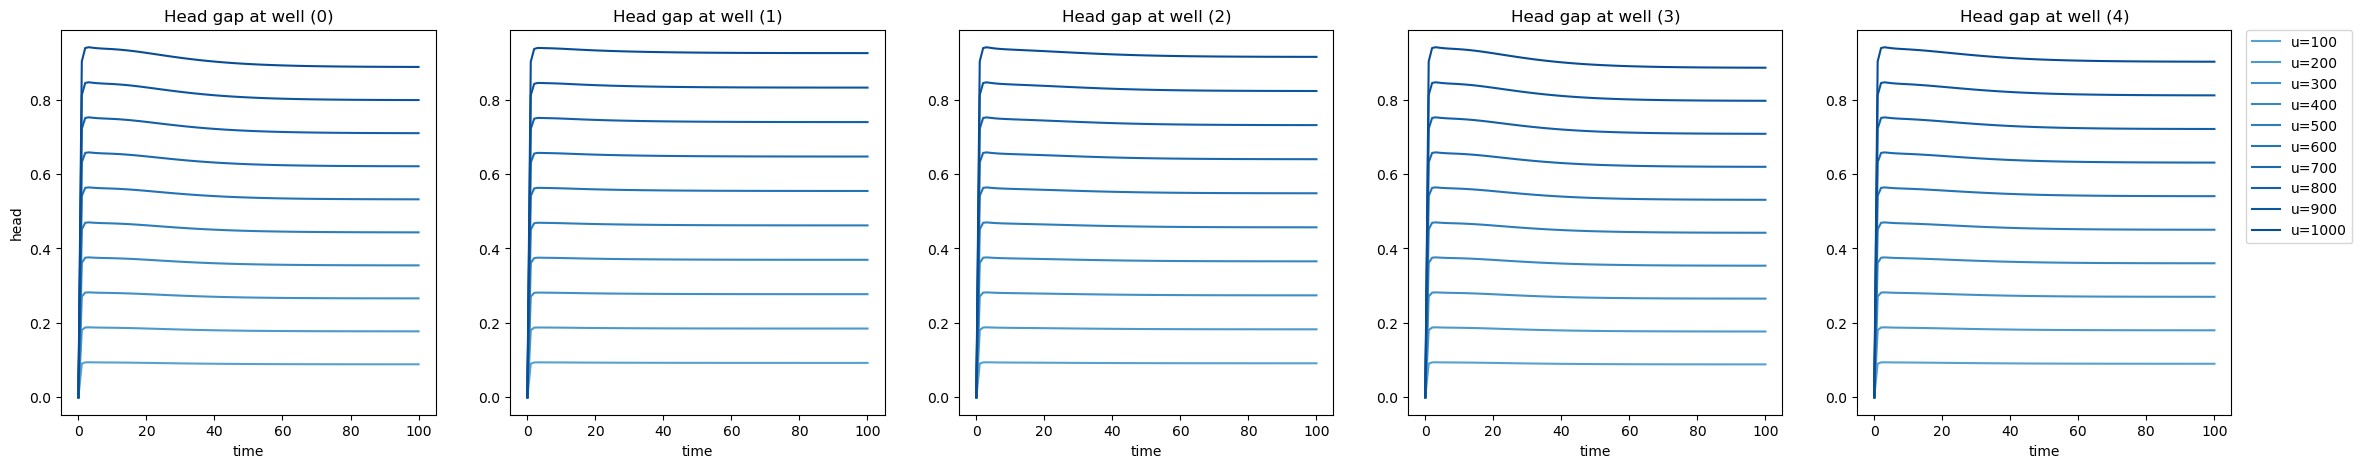

In [87]:
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    for n_i in range(n_steps_intensity):
        # ax_h.plot(response[ii][n_i][well_pos[ii], :], "b-")
        # ax_h.plot(model_response[ii][n_i][well_pos[ii], :], "b--")
        ax_h.plot(model_head[ii, n_i, well_pos[ii], :] - head[ii, n_i, ii, :], color=plt.get_cmap('Blues')((15+n_i)/(n_steps_intensity+17)), label=f"u={int((n_i+1)*intensity_step)}")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [79]:
ii=0
model_head[ii, 9, :, -1].argmin(), model_head[ii, 9, model_head[ii, 9, :, -1].argmin(), -1], head[ii, 9, model_head[ii, 9, :, -1].argmin(), -1]

(np.int64(12), np.float64(9.133073141210026), np.float64(9.355879104137431))

In [80]:
head[ii, 9, :, -1]

array([9.97617595, 9.93260638, 9.91121887, 9.93382336, 9.97679556, 9.93260638, 9.78697089, 9.68240762, 9.79296603, 9.93477288, 9.91121887, 9.68240762, 9.3558791 , 9.69563777, 9.91445643, 9.93382336, 9.79296603, 9.69563777, 9.79858505, 9.93591253, 9.97679556, 9.93477288, 9.91445643, 9.93591253, 9.97738358])

#### Plot cost gap

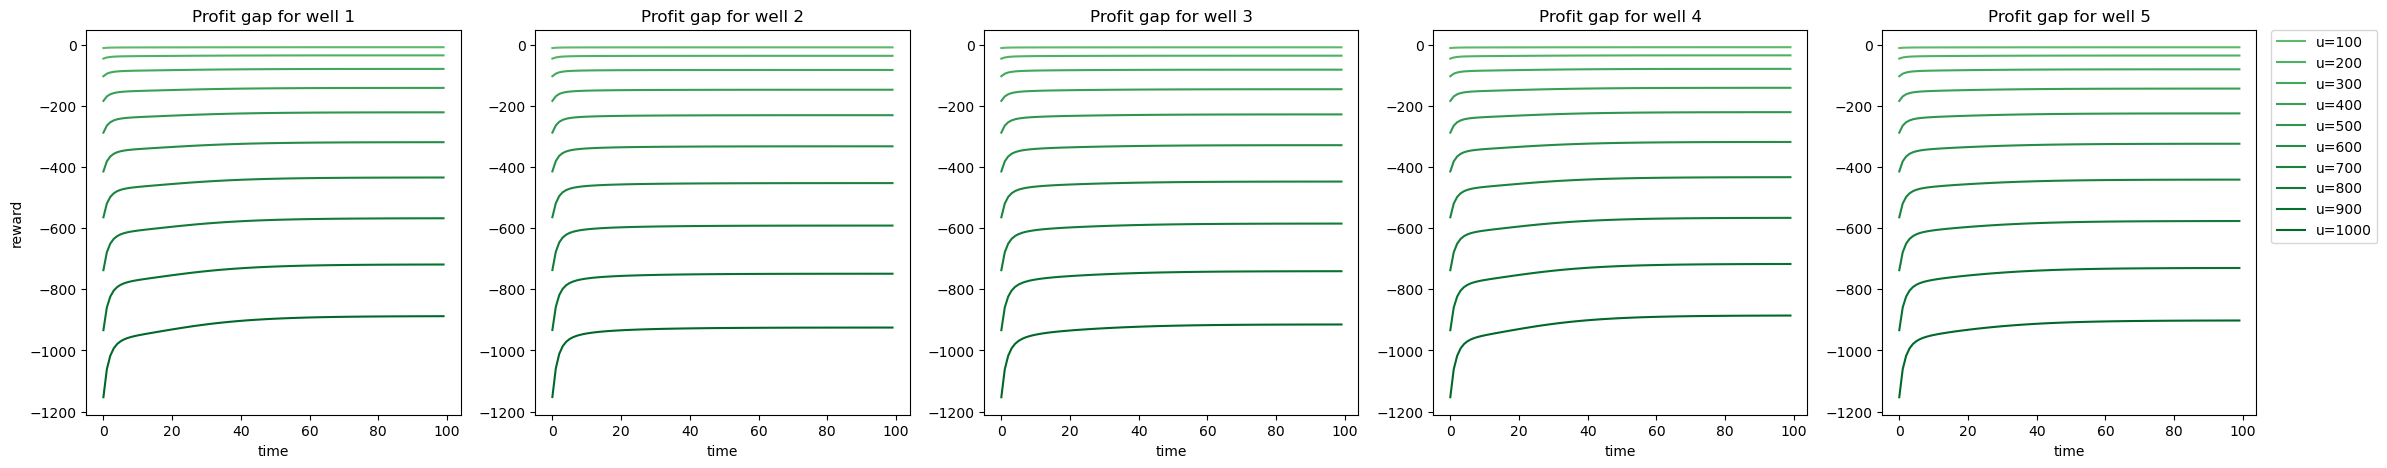

In [ ]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("time")
    if ii == 0:
        ax_p.set_ylabel("reward")
    for n_i in range(n_steps_intensity):
        ax_p.plot(model_cost[ii, n_i, model.well_to_agent[ii], :] - cost[ii, n_i, model.well_to_agent[ii], :], color=plt.get_cmap('Greens')((15+n_i)/(n_steps_intensity+17)), label=f"u={int((n_i+1)*intensity_step)}")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Search for patterns

The head gap looks more or less linear in the pumping rate, and the cost gap quadratic

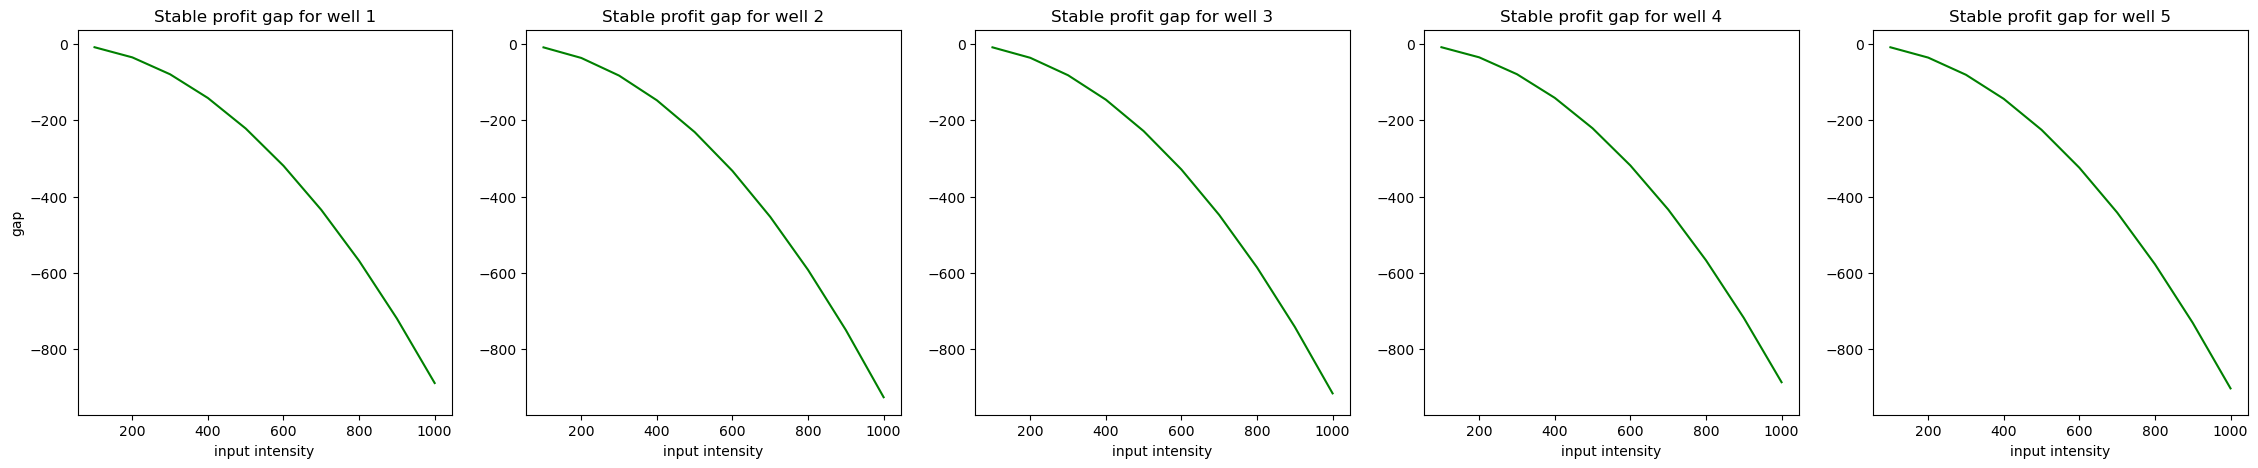

In [ ]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("input intensity")
    if ii == 0:
        ax_p.set_ylabel("gap")
    ax_p.plot(intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity), model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1], color="green")

Fit quadratic function

In [ ]:
from scipy.optimize import least_squares
params = []
intensities = intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity)
for ii in range(n_well):
    gap = model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1]
    res = least_squares(lambda x : (intensities*(x*intensities)) - gap, x0 = 0)
    params.append(res.x)

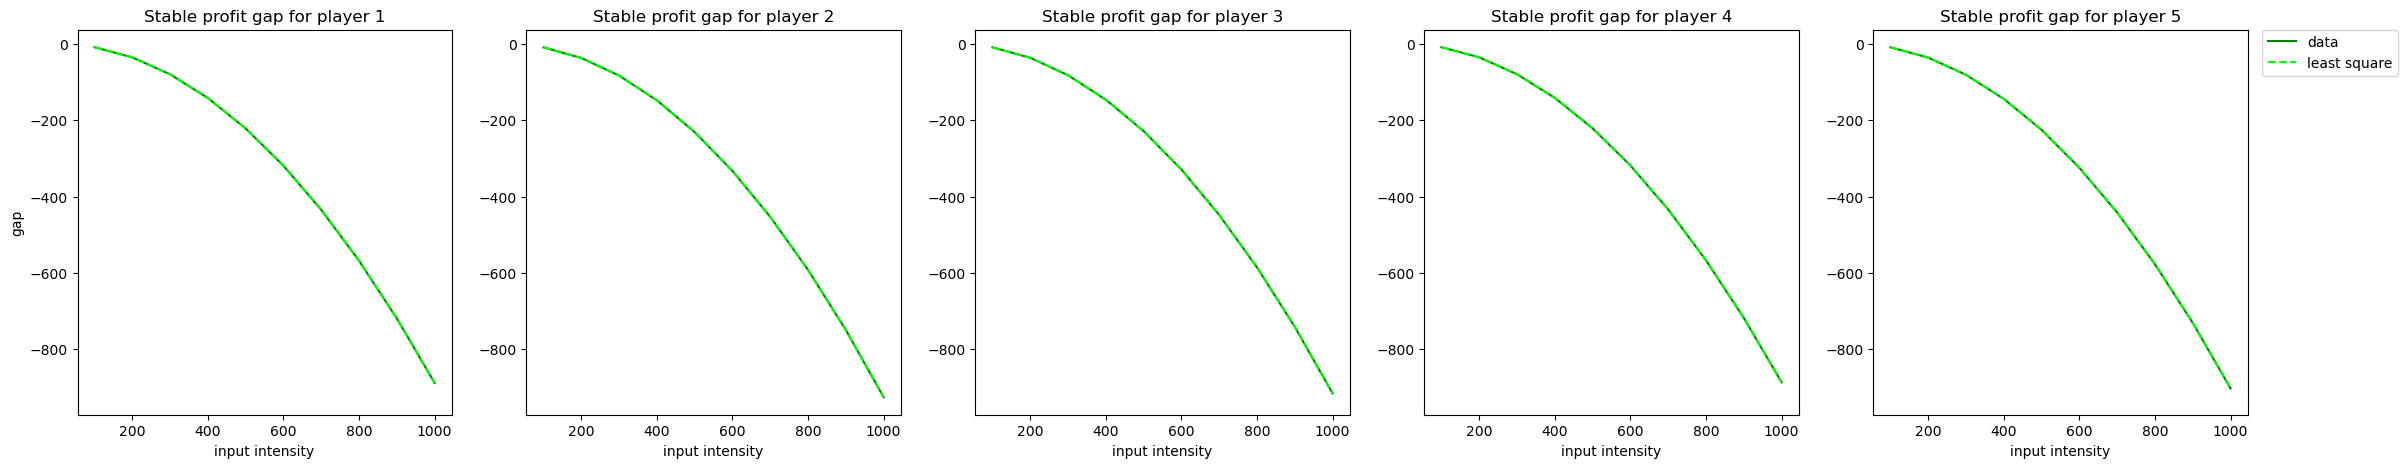

In [ ]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for player {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("input intensity")
    if ii == 0:
        ax_p.set_ylabel("gap")
    intensities = intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity)
    ax_p.plot(intensities, model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1], color="green", label="data")
    ax_p.plot(intensities, intensities*(params[ii]*intensities), color="lime", linestyle="--", label="least square")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [ ]:
params

[array([-0.00088779]),
 array([-0.00092503]),
 array([-0.00091488]),
 array([-0.00088567]),
 array([-0.00090186])]

In [ ]:
intensities = np.tile(intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity), n_well)
gap = np.hstack([model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1] for ii in range(n_well)])
res = least_squares(lambda x : (intensities*(x*intensities) - gap), x0 = 0)
c_u = res.x

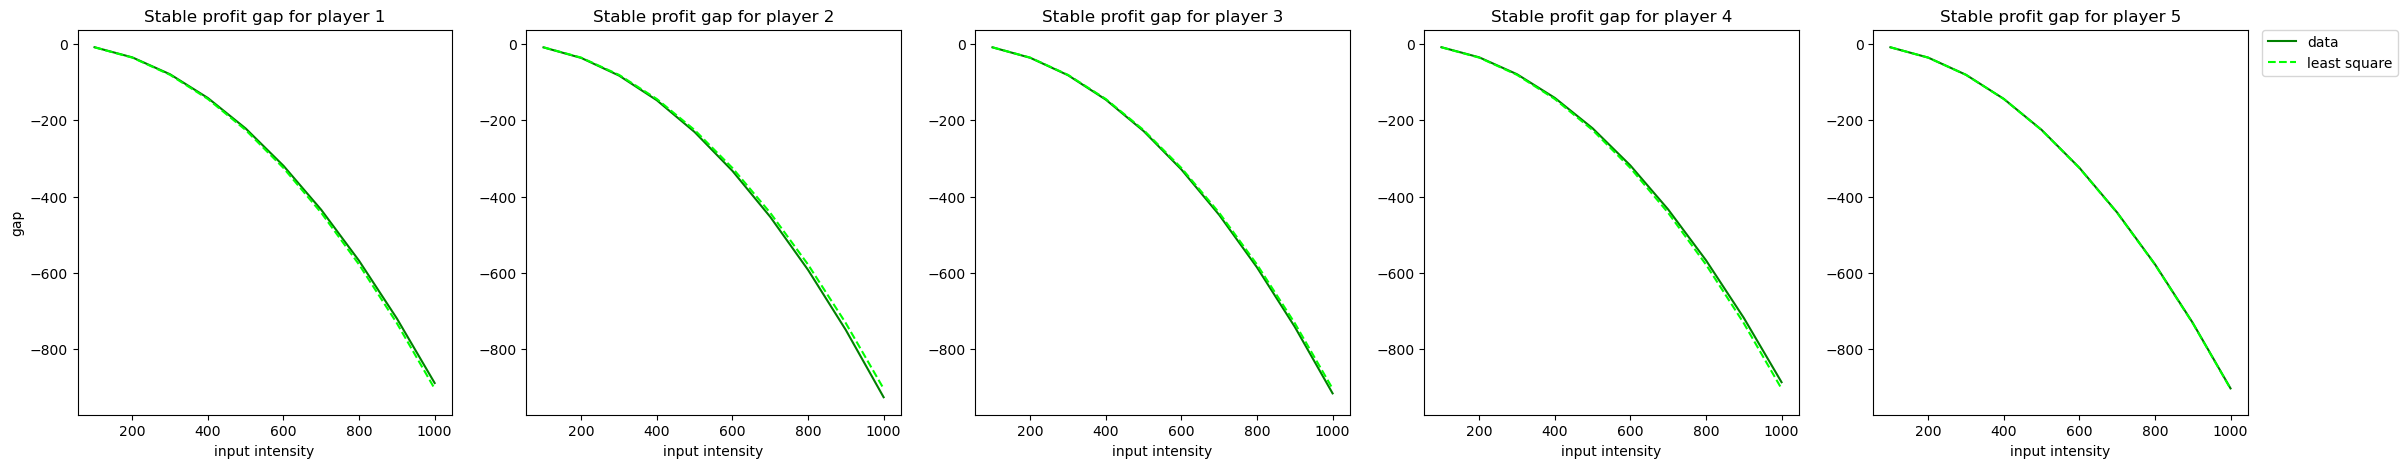

In [ ]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for player {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("input intensity")
    if ii == 0:
        ax_p.set_ylabel("gap")
    intensities = intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity)
    ax_p.plot(intensities, model_cost[ii, :, model.well_to_agent[ii], -1] - cost[ii, :, model.well_to_agent[ii], -1], color="green", label="data")
    ax_p.plot(intensities, intensities*(c_u*intensities), color="lime", linestyle="--", label="least square")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Test Gap w.r.t. cell size

In [ ]:
setups = ["Components/Setup/cell_size_variation/4x4.json", "Components/Setup/cell_size_variation/5x5.json", "Components/Setup/cell_size_variation/10x10.json", "Components/Setup/cell_size_variation/20x20.json", "Components/Setup/cell_size_variation/25x25.json"]
n_sizes = len(setups)
u_bar = 1000

In [ ]:
models = []
for parameter_file in setups:
    models.append(SquareCoarseModel(parameter_file, boundary_condition="Constant Head"))

In [ ]:
# Compute expected heads for those setup
system.state = system.initial_state.copy()
model_head_cs = []
model_cost_cs = []
for ii in range(n_well):
    model_head_cs.append([])
    model_cost_cs.append([])
    for s in trange(n_sizes):
        model_head_cs[ii].append(np.hstack((models[s].translate_state(system.get_state()[0,:,:]), np.zeros((models[s].nx, T)))))
        model_cost_cs[ii].append(np.zeros((models[s].n_agent, T)))
        intensity = u_bar
        B = sp.hstack(models[s].B_v)
        for k in range(T):
            models[s].state = model_head_cs[ii][s][:, [k]]
            input = models[s].input_to_well.T @ (intensity*base_command[ii][:, [k]])
            model_head_cs[ii][s][:, k+1] = (models[s].A @ model_head_cs[ii][s][:, [k]] + B @ input + models[s].C).flatten()
            model_cost_cs[ii][s][:, k] = models[s].compute_cost(intensity*base_command[ii][:, [k]]).flatten()

100%|██████████| 5/5 [00:00<00:00, 11.32it/s]


In [ ]:
# Compute real heads and costs
head_hr = np.array([np.hstack((system.get_state()[0,:,:].reshape(-1,1), np.zeros((system.get_state()[0,:,:].shape[0]*system.get_state()[0,:,:].shape[1], T))))] * n_well)
cost_hr = np.array([np.zeros((model.n_agent, T))] * n_well)
for ii in range(n_well):
    system.state = system.initial_state.copy()
    intensity = u_bar
    for k in trange(T):
        system.apply_command(intensity*base_command[ii][:, [k]])
        head_hr[ii, :, k+1] = system.get_state()[0,:,:].flatten()
        cost_hr[ii, :, k] = system.compute_cost(intensity*base_command[ii][:, [k]]).flatten()

100%|██████████| 100/100 [00:07<00:00, 12.86it/s]


#### Plot head gaps for the different setups

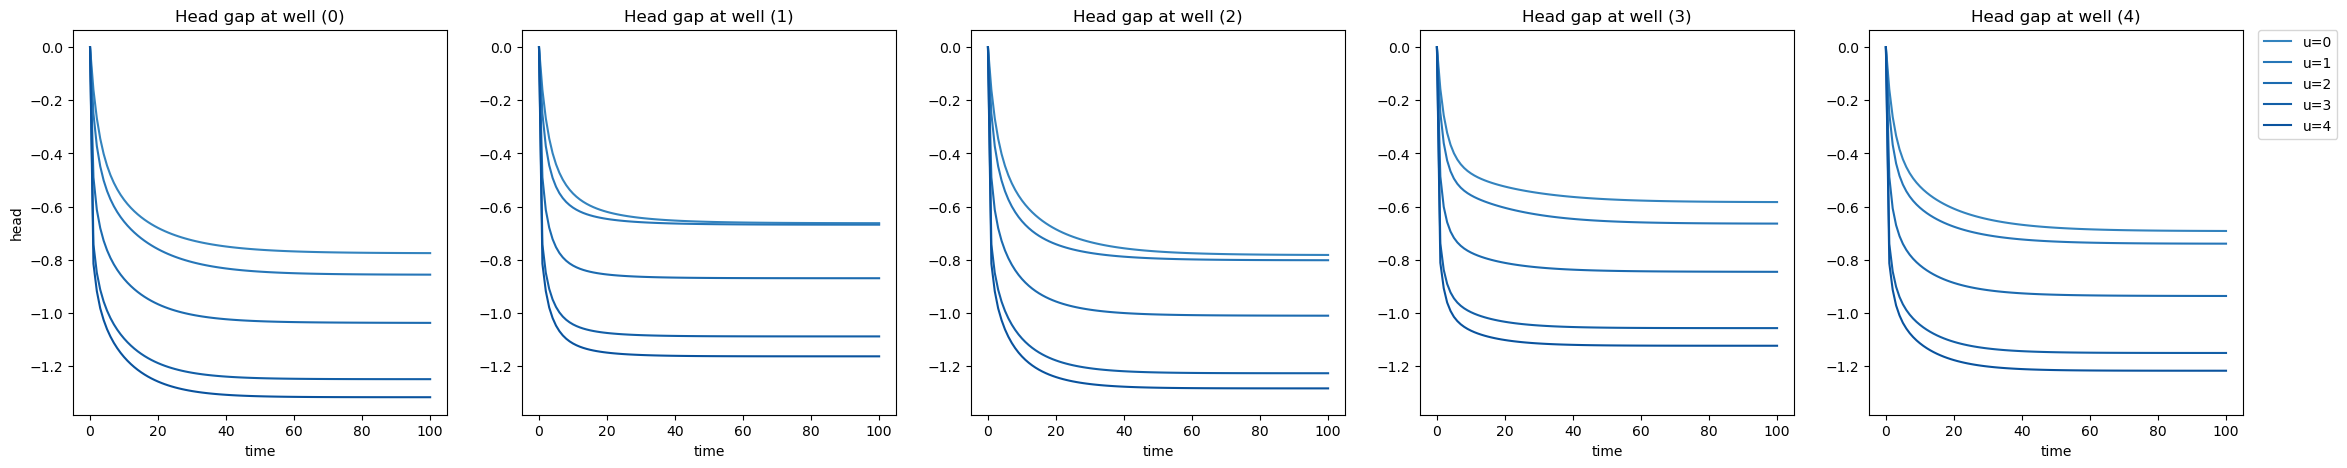

In [ ]:
well_pos_hr = [49*49, 80*70, 35*60, 50*45, 45*62]
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    for s in range(n_sizes):
        well_pos = np.nonzero(models[s].well_to_cell.T)[1]
        ax_h.plot(model_head_cs[ii][s][well_pos[ii], :] - head_hr[ii, well_pos_hr[ii], :], color=plt.get_cmap('Blues')((15+s)/(n_sizes+17)), label=f"u={int(s)}")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

#### Plot cost gap

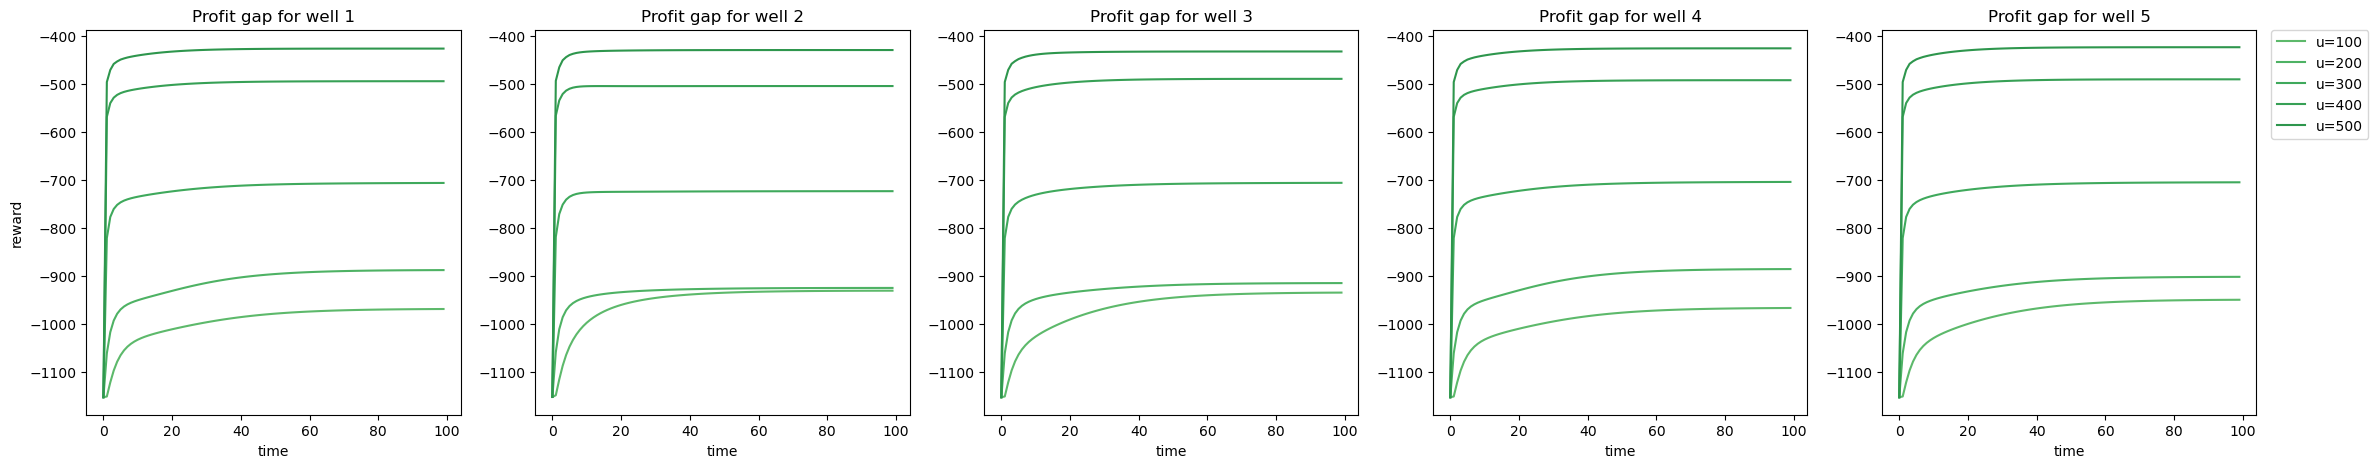

In [ ]:
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("time")
    if ii == 0:
        ax_p.set_ylabel("reward")
    for s in range(n_sizes):
        ax_p.plot(model_cost_cs[ii][s][model.well_to_agent[ii], :] - cost_hr[ii, model.well_to_agent[ii], :], color=plt.get_cmap('Greens')((15+s)/(n_steps_intensity+17)), label=f"u={int((s+1)*intensity_step)}")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Search for patterns

The head gap looks more or less linear in the pumping rate, and the cost gap quadratic

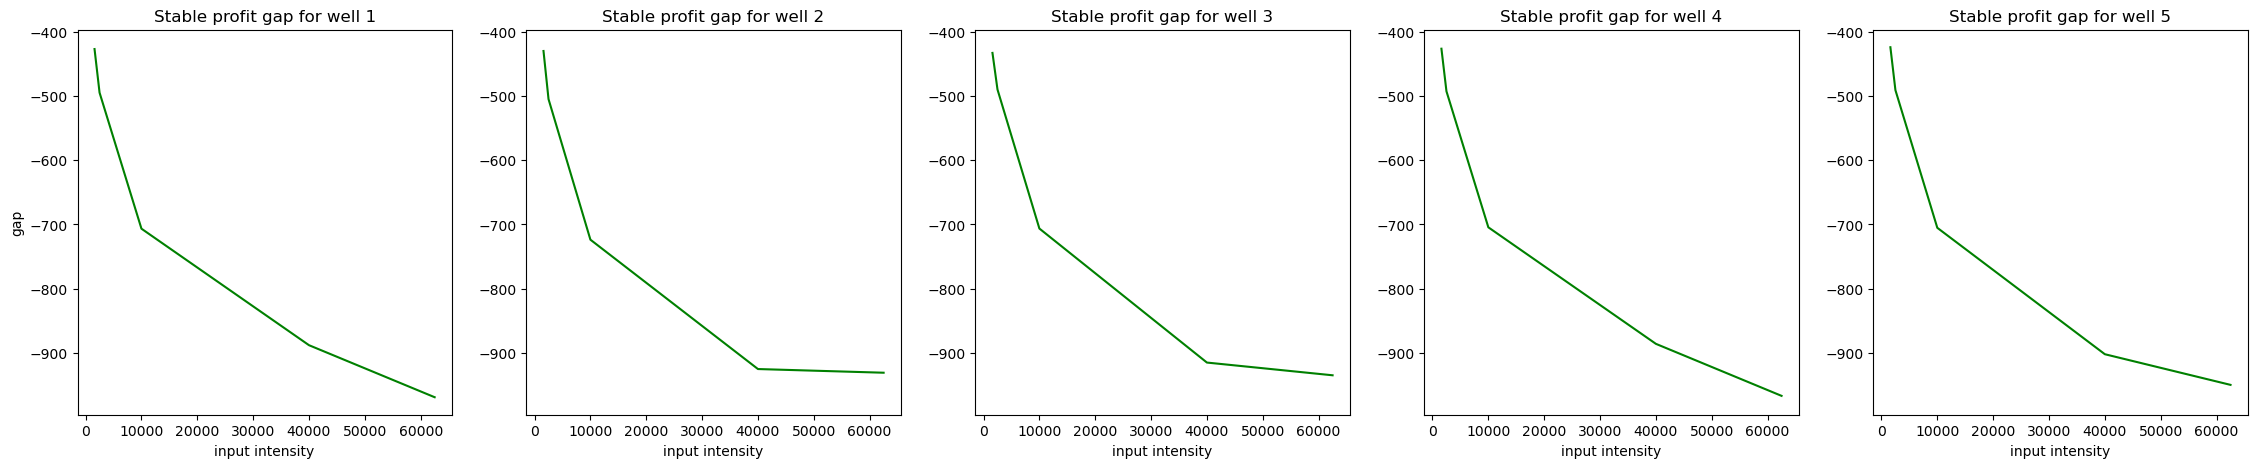

In [ ]:
sizes = [(1000*1000)/(4*4), (1000*1000)/(5*5), (1000*1000)/(10*10), (1000*1000)/(20*20), (1000*1000)/(25*25)]
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("input intensity")
    if ii == 0:
        ax_p.set_ylabel("gap")
    ax_p.plot(sizes, np.array(model_cost_cs)[ii, :, model.well_to_agent[ii], -1] - cost_hr[ii, model.well_to_agent[ii], -1], color="green")

In [ ]:
sizes_list = np.tile(sizes, n_well)
gap = np.hstack([np.array(model_cost_cs)[ii, :, model.well_to_agent[ii], -1] - cost_hr[ii, model.well_to_agent[ii], -1] for ii in range(n_well)])
res = least_squares(lambda x : -(x[0]*np.log(sizes_list) + x[1] - gap), x0 = [0,0])
c_A = res.x

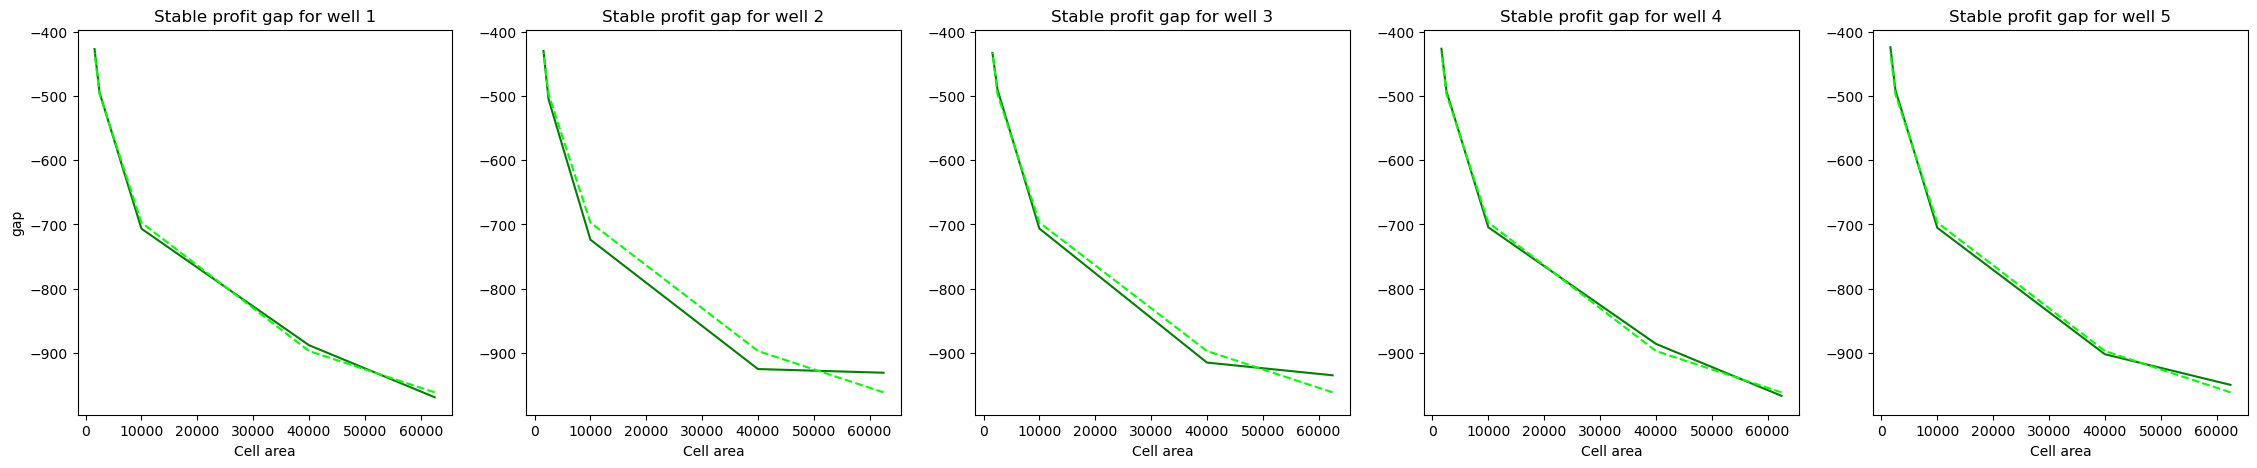

In [ ]:
sizes = np.array([(1000*1000)/(4*4), (1000*1000)/(5*5), (1000*1000)/(10*10), (1000*1000)/(20*20), (1000*1000)/(25*25)])
fig_p = plt.figure(figsize=(25+3,5))
ax_p = None
for ii in range(n_well):
    ax_p = fig_p.add_subplot(1, 5, ii+1, sharey=ax_p)
    ttl = f"Stable profit gap for well {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("Cell area")
    if ii == 0:
        ax_p.set_ylabel("gap")
    ax_p.plot(sizes, np.array(model_cost_cs)[ii, :, model.well_to_agent[ii], -1] - cost_hr[ii, model.well_to_agent[ii], -1], color="green")
    ax_p.plot(sizes, c_A[0]*np.log(sizes) + c_A[1], color="lime", linestyle="--", label="least square")

As expected given the Theis solution, the gap and the size of the cell are related by a logarithmic function.

# Cost augmentation

We can then augment the cost using these observation. We add the correction term $\delta(u,A)$, with:

$\begin{cases} \delta(u,\bar A) = c^u(\bar A) u^2 \qquad &\text{with } \bar A \in \mathbb R^+\\
\delta(\bar u,A)\ = c^A_1(\bar u) \log(A) + c^A_2(\bar u) \qquad &\text{with } \bar u \in \mathbb R^- \end{cases}$

So finally, if we compute $c^A_1(\bar u)$, $c^A_2(\bar u)$ for some $\bar u$, we have:

$\delta(u,A) = \left(c^A_1(\bar u) \log(A) + c^A_2(\bar u)\right)\left(\frac{u}{\bar u}\right)^2$

Let's verify this relation

In [ ]:
(c_A[0]*np.log((1000/model.n_col)*(1000/model.n_row)) + c_A[1])/(u_bar**2), c_u

(np.float64(-0.0008972689241796068), array([-0.00090305]))

Ok! Very similar.

Now, let's augment the cost

In [ ]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [ ]:
n_well_per_input = [model.input_to_well[model.well_to_agent==v, :].sum(axis=0) for v in range(model.n_agent)]
n_well_per_input = [n_w_p_i[n_w_p_i>0] for n_w_p_i in n_well_per_input]

In [ ]:
R_v = [(-c_u)*np.diag(n_w_p_i) for n_w_p_i in n_well_per_input]
R_v

[array([[0.00180609]]),
 array([[0.00090305, 0.        ],
        [0.        , 0.00090305]]),
 array([[0.00090305]])]

In [ ]:
model_copy = copy.deepcopy(model)
def compute_augmented_cost(u: np.ndarray) -> np.ndarray:
    cost = np.zeros((model_copy.n_agent, 1))
    for v in range(model_copy.n_agent):
        input_indices = np.nonzero(model_copy.well_to_cell[:,model_copy.well_to_agent==v].T)[1]
        cost[v] = (-model_copy.extraction_cost[v] * (model_copy.initial_state[input_indices] -\
            model_copy.state[input_indices]) * u[model_copy.well_to_agent==v] + \
                model_copy.production_profit[v] * u[model_copy.well_to_agent==v] -\
                    c_u * u[model_copy.well_to_agent==v]**2).sum()
    return cost
model_copy.compute_cost = compute_augmented_cost

In [ ]:
system_bis = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")

In [ ]:
# Initialize Controller
Q_v, R_v_i,R_v_minus, M_v, L_v = model.get_cost_matrices("look_ahead")
R_v = [R + R_i for R, R_i in zip(R_v, R_v_i)]
controller = LTI_LQRc_RHG(
    parameter_file,
    model_copy.A.toarray(), [B.toarray() for B in model_copy.B_v], model_copy.C,
    model_copy.H_x, model_copy.h_x, model_copy.H_u_v, model_copy.h_u_v,
    Q_v, R_v, R_v_minus, M_v, L_v,
    solver='fbrs'
)

In [ ]:
np.linalg.eigvals((controller.F.T + controller.F).toarray())[np.linalg.eigvals((controller.F.T + controller.F).toarray())>0], \
np.linalg.eigvals((controller.F.T + controller.F).toarray())[np.linalg.eigvals((controller.F.T + controller.F).toarray())<0]

(array([10.09547086,  9.28315162,  8.93994169,  8.7315907 ,  8.58077366,  8.46404977,  7.1677193 ,  8.37222506,  8.29787688,  8.23742861,  8.18726758,  8.14559952,  8.1104311 ,  8.08075567,  8.05539708,  8.03375209,  8.01509562,  6.07797325,  7.99904838,  7.98514907,  7.97314995,  7.96275114,  6.03684875,  7.95378605,  7.94605749,  7.9338383 ,  7.93945139,  7.92913996,  7.92527328,  7.92218607,  7.91816849,  7.91718156,  7.91982832,  5.67425284,  5.51748841,  5.42086419,  5.29666873,  5.38396015,  5.21154445,  5.16662597,  5.15682044,  5.05023406,  5.02975064,  4.97086731,  4.94940322,  4.90157809,  4.86412853,  4.82548857,  4.80757048,  4.78487935,  4.73971072,  4.71606643,  4.71026352,  4.68549191,  4.63055387,  4.64603853,  4.63980207,  4.60076209,  4.59225869,  4.56717347,  4.56291229,  4.53814541,  4.54723218,  4.51295929,  4.50842042,  4.50925887,  4.49104014,  4.2429386 ,  4.24380059,  4.24525292,  4.2473203 ,  4.4770604 ,  4.2500372 ,  4.4719141 ,  4.25345216,  4.25762449,  4.4

In [ ]:
# Initialize receding horizon
receding_horizon = RecedingHorizon(system_bis, model_copy, controller, parameter_file)

Simulation progress: 100%|██████████| 200/200 [00:45<00:00,  4.38it/s]
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:113: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_h.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:114: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_q.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:115: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_p.show()


array([[[9.999736 , 9.999471 , 9.999206 , ..., 9.998609 , 9.999072 , 9.9995365],
        [9.999471 , 9.998941 , 9.998411 , ..., 9.997217 , 9.998145 , 9.999072 ],
        [9.999207 , 9.998413 , 9.997619 , ..., 9.995826 , 9.997216 , 9.998609 ],
        ...,
        [9.999255 , 9.998509 , 9.997764 , ..., 9.992589 , 9.995069 , 9.997537 ],
        [9.999503 , 9.999006 , 9.998508 , ..., 9.995049 , 9.996706 , 9.998355 ],
        [9.999751 , 9.999503 , 9.999254 , ..., 9.997522 , 9.998351 , 9.999177 ]]], shape=(1, 100, 100), dtype=float32)

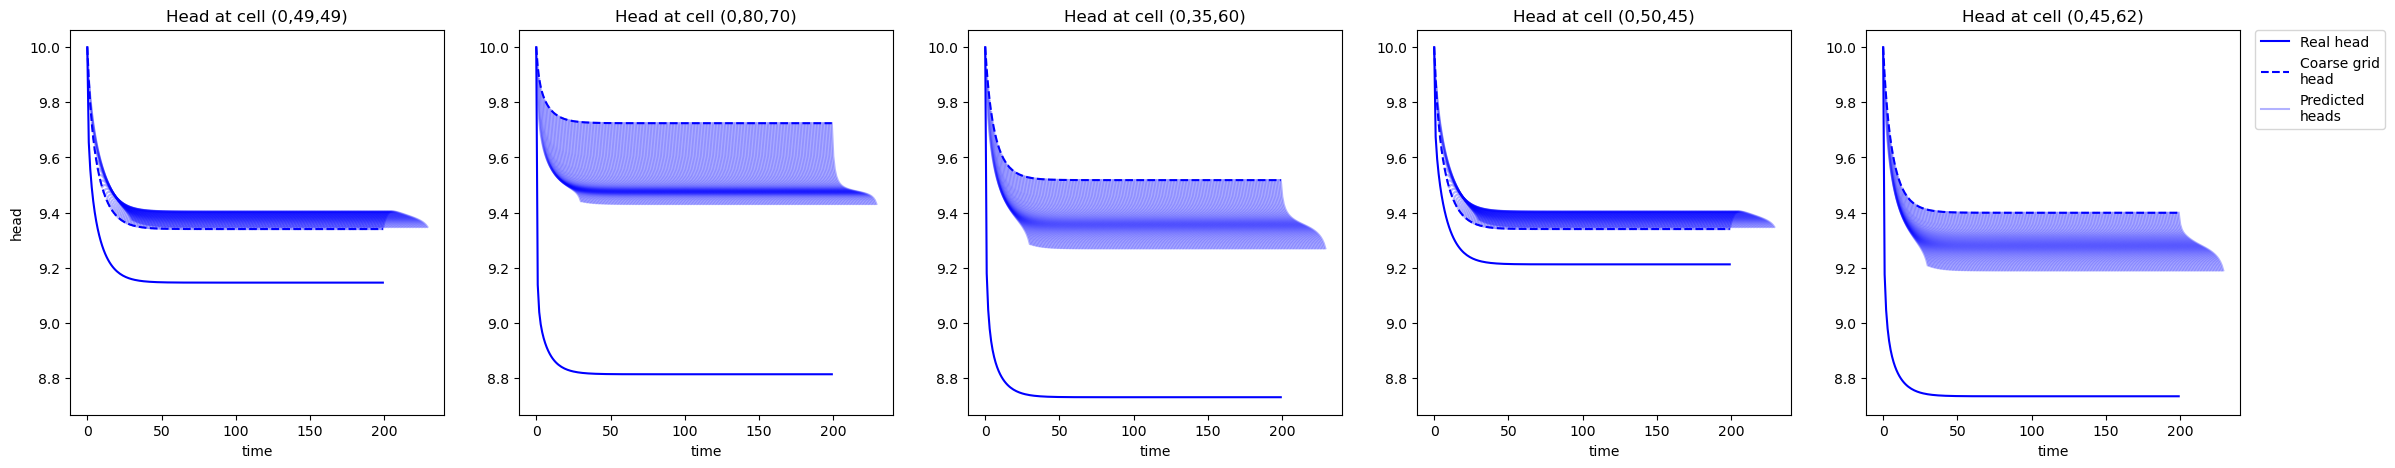

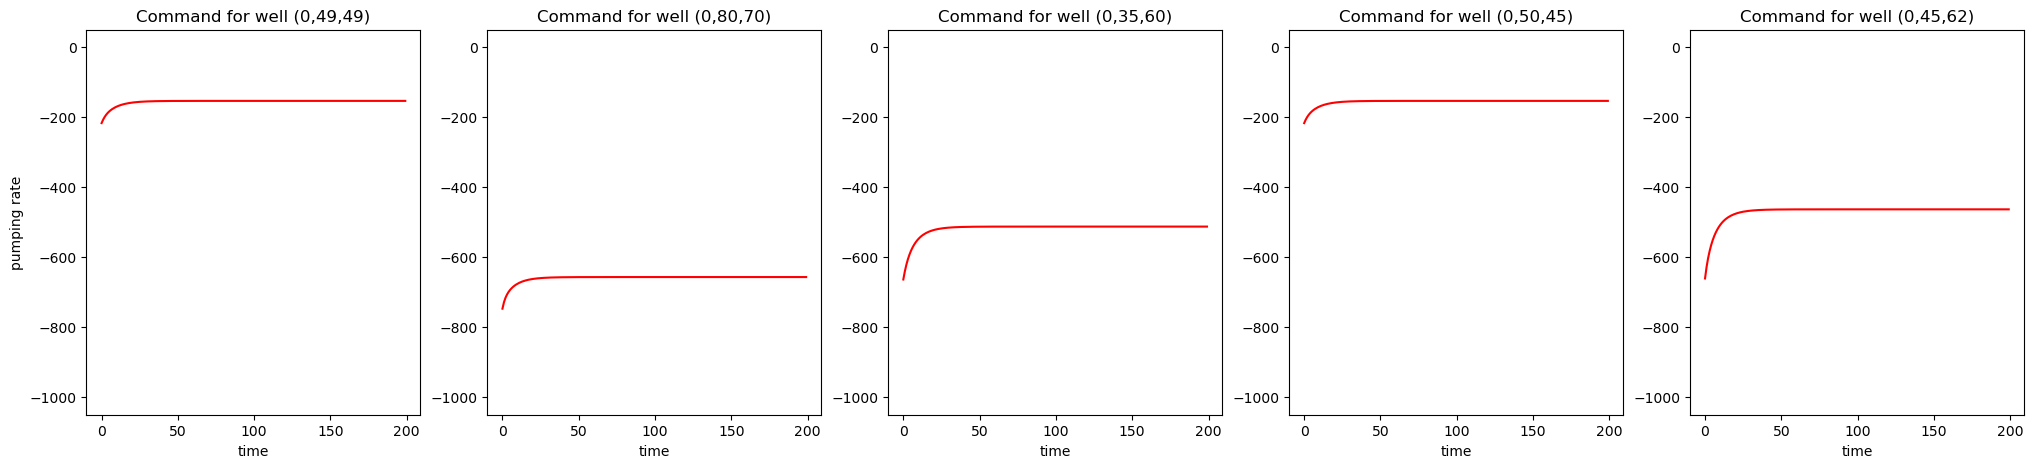

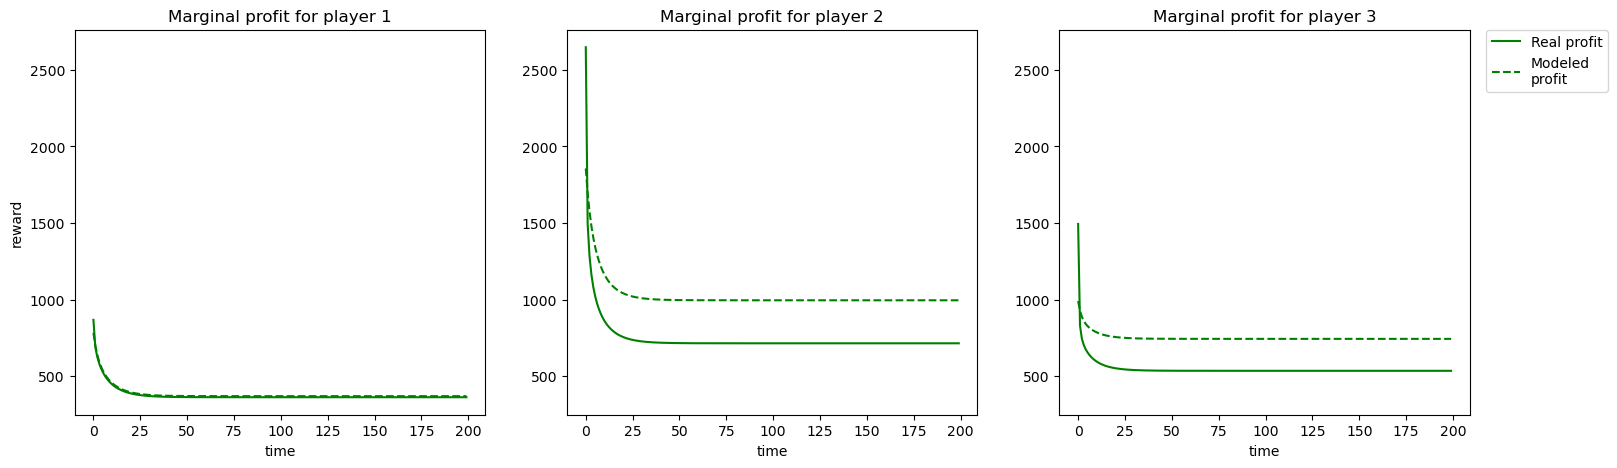

In [ ]:
# Run loop
receding_horizon.run(time_period=200, display_results=True)

In [ ]:
model.well_to_agent

array([0, 2, 1, 0, 1])

In [ ]:
data = np.load("run_data/run_20250528-110603/result_data.npz")

In [ ]:
data['q_rates'][1,-1], data['avg_h_wells'][1,-1]

(np.float64(-1000.0), np.float64(9.547668921947482))

In [ ]:
(10-data['avg_h_wells'][0,-1])*data['q_rates'][0,-1]*2 - 2*data['q_rates'][0,-1]*2 + c_u * data['q_rates'][0,-1]*2*data['q_rates'][0,-1]*2,\
(10-data['avg_h_wells'][1,-1])*data['q_rates'][1,-1] - 2*data['q_rates'][1,-1] + c_u * data['q_rates'][1,-1]*data['q_rates'][1,-1]

(array([-25.56032547]), array([644.62211287]))

In [ ]:
compute_augmented_cost(data['q_rates'][:,[-1]])

array([[-263.9521221 ],
       [-356.33076984],
       [-644.62211287]])

In [ ]:
data['real_profit'][:,-1]

array([ 188.61815565, -615.69627957,  128.5610199 ])

For me, the gap that is still there comes from the effect of the interactions between the wells.

In [ ]:
c_u * data['q_rates'][0,-1]*2*data['q_rates'][0,-1]*2, c_u * data['q_rates'][1,-1]*data['q_rates'][1,-1]

(array([-579.02489514]), array([-903.04680907]))

In [ ]:
(data['real_profit'][0,-1]-data['model_profit'][0,-1])/(c_u * data['q_rates'][0,-1]*2*data['q_rates'][0,-1]*2), \
    (data['real_profit'][2,-1]-data['model_profit'][2,-1])/(c_u * data['q_rates'][1,-1]*data['q_rates'][1,-1])

(array([0.13010488]), array([0.5714666]))

# Correction on the heads

In [ ]:
well_pos = np.nonzero(model.well_to_cell.T)[1]
inputs = np.hstack([model.input_to_well.T@(base_command[ii][:,[-1]]*intensity_step*np.linspace(1, n_steps_intensity, n_steps_intensity)) for ii in range(n_well)])
gap = np.hstack([model_head[ii, :, well_pos, -1] - head[ii, :, well_pos, -1] for ii in range(n_well)])
res = np.linalg.lstsq(inputs.T,gap.T)
C_u = res[0].T

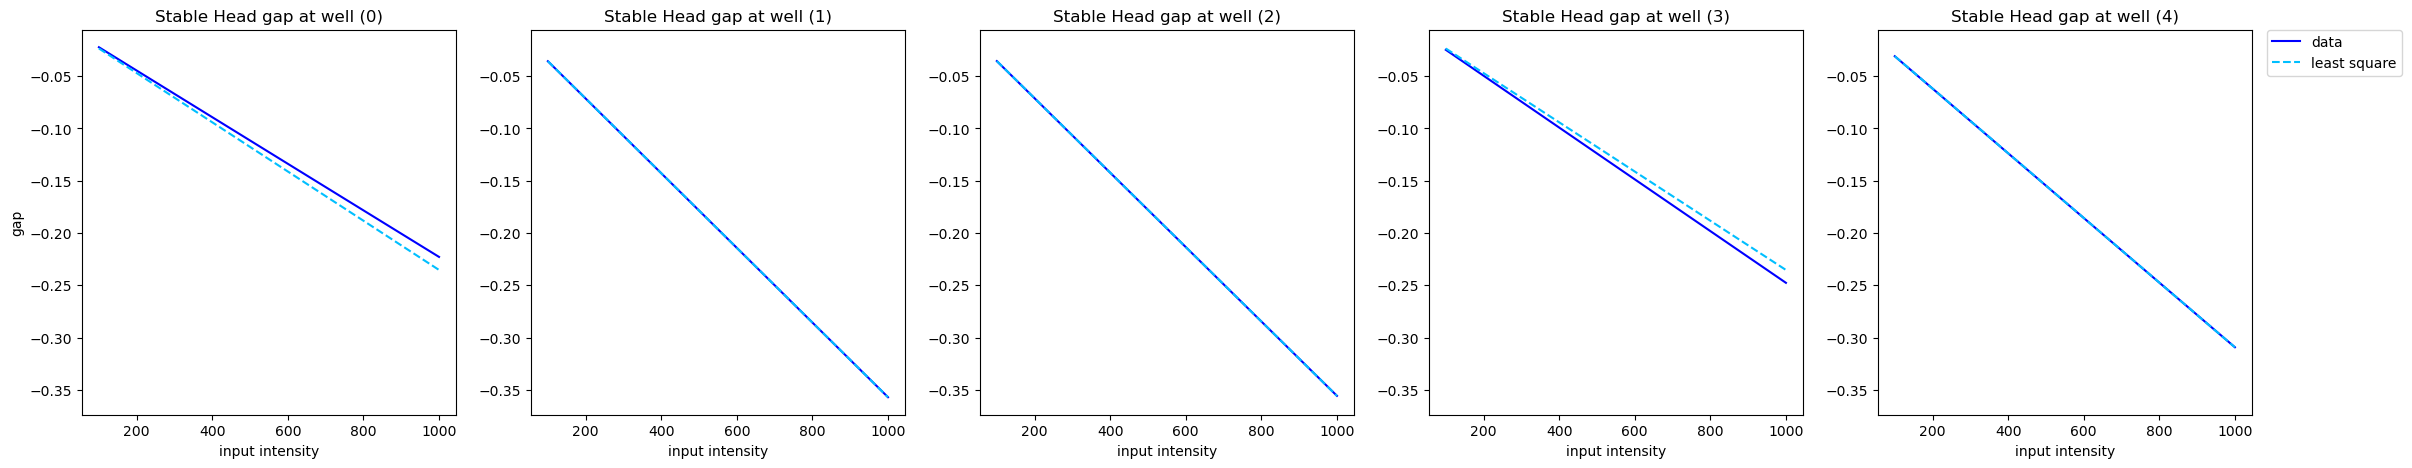

In [ ]:
estimated_gap = np.split((C_u @ inputs), 10*np.linspace(1,4,4, dtype=int), axis=1)
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Stable Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("input intensity")
    if ii == 0:
        ax_h.set_ylabel("gap")
    ax_h.plot(intensities, model_head[ii, :, well_pos[ii], -1] - head[ii, :, well_pos[ii], -1], color="blue", label="data")
    ax_h.plot(intensities, estimated_gap[ii][ii, :], color="deepskyblue", linestyle="--", label="least square")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

##### Cell-size dependency --> TODO: think more about this

In [ ]:
np.log(sizes_list[0])/gap[:,0], np.log(sizes_list[1])/gap[:,1], np.log(sizes_list[2])/gap[:,2]

(array([ -14.24422781, -133.13035474,  -35.72327263,  -35.72327263,  -35.72327263]),
 array([ -12.37450856, -103.50857996,  -45.23806455,  -12.37450856,  -28.9385105 ]),
 array([  -8.87390171, -122.98579066,  -31.06905859,  -16.317935  ,  -27.49375536]))

In [ ]:
sizes_list = np.tile(sizes, n_well)
log_sizes_list = np.log(np.kron(sizes_list,np.ones((5,1))))
gap = np.hstack([np.hstack([model_head_cs[ii][s][[np.nonzero(models[s].well_to_cell.T)[1]], [-1]].T for s in range(n_sizes)]) - head_hr[ii, [well_pos_hr[ii]], [-1]].T for ii in range(n_well)])
res = least_squares(lambda x : -np.linalg.norm((x[:n_well,np.newaxis]*log_sizes_list + x[n_well:,np.newaxis] - gap)), x0 = np.zeros(2*n_well))
C_A = res.x

In [ ]:
gap

array([[-0.77525591, -0.85632772, -1.03791327, -1.24987321, -1.31784984, -0.09135769, -0.11078396, -0.08329897, -0.10120143, -0.12515625, -0.31604484, -0.24116237, -0.30336817, -0.3521012 , -0.31749154, -0.11688999, -0.66409368, -0.37219647, -0.56866531, -0.63541998, -0.22576431, -0.2828179 , -0.25163782, -0.32646983, -0.37099611],
       [-0.08294819, -0.10237446, -0.07488947, -0.09279193, -0.11674675, -0.66248887, -0.6682139 , -0.86982546, -1.08886231, -1.16389356, -0.11749822, -0.06305517, -0.06925299, -0.08375551, -0.07614596,  0.03709337,  0.08985958,  0.09947304,  0.08413313,  0.08616585, -0.02721769, -0.04129724, -0.0175136 , -0.03444889, -0.03408811],
       [-0.30912403, -0.23424156, -0.29644736, -0.34518038, -0.31057073, -0.11898691, -0.06454385, -0.07074168, -0.0852442 , -0.07763465, -0.78217673, -0.80198131, -1.01086791, -1.22753851, -1.28456876, -0.00369928, -0.04200752, -0.03254275, -0.10815683, -0.08460464, -0.69189619, -0.2548973 , -0.45317815, -0.43715692, -0.37076933]

In [ ]:
C_A[:n_well,np.newaxis]*log_sizes_list + C_A[n_well:,np.newaxis]

array([[-0.43873831, -0.43723553, -0.43256745, -0.42789937, -0.42639659, -0.43873831, -0.43723553, -0.43256745, -0.42789937, -0.42639659, -0.43873831, -0.43723553, -0.43256745, -0.42789937, -0.42639659, -0.43873831, -0.43723553, -0.43256745, -0.42789937, -0.42639659, -0.43873831, -0.43723553, -0.43256745, -0.42789937, -0.42639659],
       [-0.19958509, -0.19925833, -0.19824333, -0.19722833, -0.19690157, -0.19958509, -0.19925833, -0.19824333, -0.19722833, -0.19690157, -0.19958509, -0.19925833, -0.19824333, -0.19722833, -0.19690157, -0.19958509, -0.19925833, -0.19824333, -0.19722833, -0.19690157, -0.19958509, -0.19925833, -0.19824333, -0.19722833, -0.19690157],
       [-0.39229925, -0.38752319, -0.37268741, -0.35785163, -0.35307557, -0.39229925, -0.38752319, -0.37268741, -0.35785163, -0.35307557, -0.39229925, -0.38752319, -0.37268741, -0.35785163, -0.35307557, -0.39229925, -0.38752319, -0.37268741, -0.35785163, -0.35307557, -0.39229925, -0.38752319, -0.37268741, -0.35785163, -0.35307557]

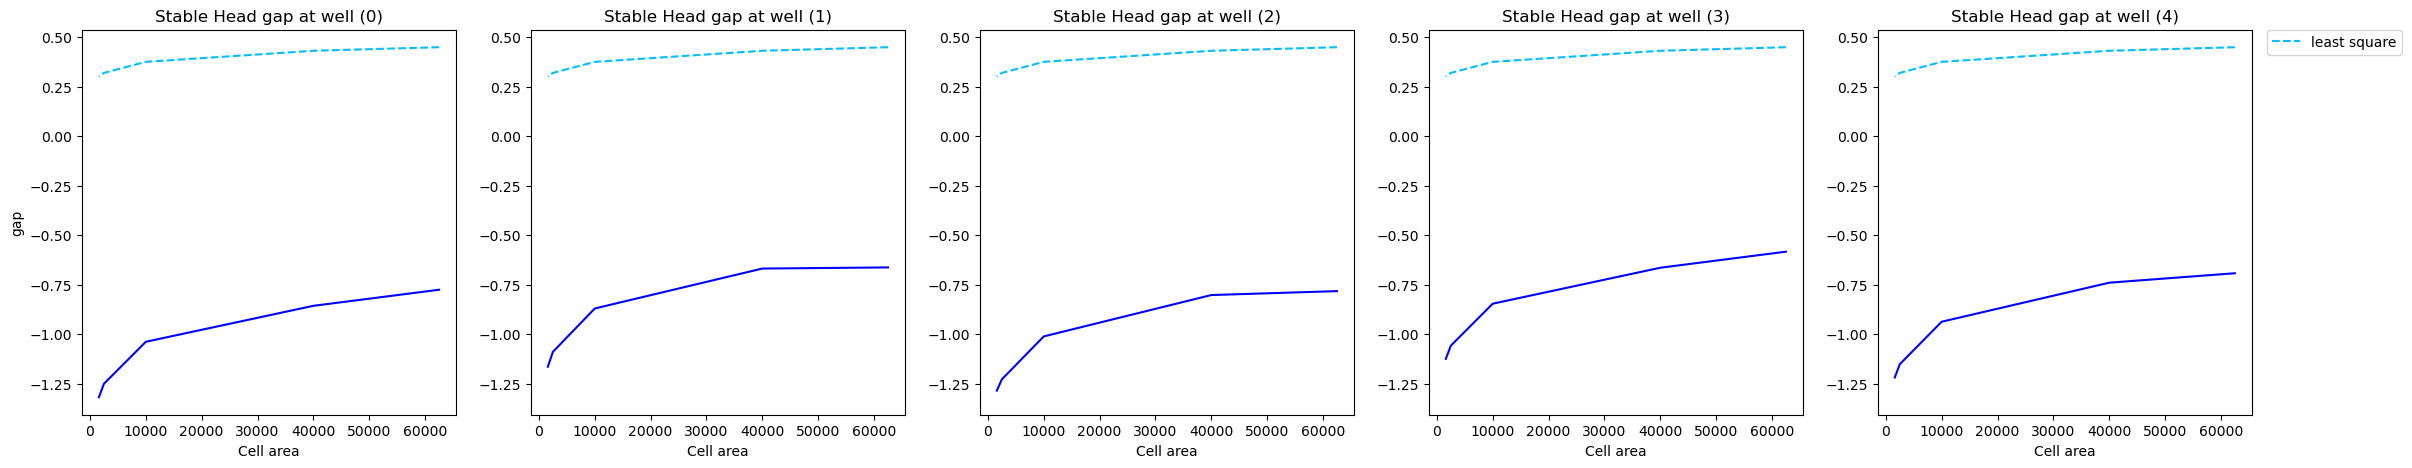

In [ ]:
sizes = np.array([(1000*1000)/(4*4), (1000*1000)/(5*5), (1000*1000)/(10*10), (1000*1000)/(20*20), (1000*1000)/(25*25)])
well_pos_hr = [49*49, 80*70, 35*60, 50*45, 45*62]
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Stable Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("Cell area")
    if ii == 0:
        ax_h.set_ylabel("gap")
    ax_h.plot(sizes, [model_head_cs[ii][s][np.nonzero(models[s].well_to_cell.T)[1][ii], -1] - head_hr[ii, well_pos_hr[ii], -1] for s in range(n_sizes)], color="blue")
    ax_h.plot(sizes, -(C_A[:n_well,np.newaxis]*np.log(sizes) + C_A[n_well:,np.newaxis])[ii], color="deepskyblue", linestyle="--", label="least square")
    # for s in range(n_sizes):
    #     well_pos = np.nonzero(models[s].well_to_cell.T)[1]
    #     ax_h.plot(model_head_cs[ii][s][well_pos[ii], :] - head_hr[ii, well_pos_hr[ii], :], color=plt.get_cmap('Blues')((15+s)/(n_sizes+17)), label=f"u={int(s)}")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

##### Test in simulation

In [ ]:
model_copy = copy.deepcopy(model)
def compute_augmented_cost(u: np.ndarray) -> np.ndarray:
    cost = np.zeros((model_copy.n_agent, 1))
    for v in range(model_copy.n_agent):
        input_indices = np.nonzero(model_copy.well_to_cell[:,model_copy.well_to_agent==v].T)[1]
        cost[v] = (-model_copy.extraction_cost[v] * (model_copy.initial_state[input_indices] -\
            model_copy.state[input_indices]) * u[model_copy.well_to_agent==v] + \
                model_copy.production_profit[v] * u[model_copy.well_to_agent==v] +\
                    (C_u @ model_copy.input_to_well.T @ u)[model_copy.well_to_agent==v] * u[model_copy.well_to_agent==v]).sum()
    return cost
model_copy.compute_cost = compute_augmented_cost

In [ ]:
R_v

[array([[0.00205609]]),
 array([[0.00115305, 0.        ],
        [0.        , 0.00115305]]),
 array([[0.00115305]])]

In [ ]:
# Split correction coefficients into self-contribution and impact of others
input_to_agent = model_copy.input_to_well.T @ model_copy.well_to_agent
D_vv, D_v_minus_v = [], []
for v in range(model_copy.n_agent):
    D_uv = np.split((model_copy.input_to_well.T[input_to_agent==v, :]) @ C_u, np.cumsum(model_copy.nu_v)[:-1], axis=1)
    D_vv.append(D_uv[v])
    D_v_minus_v.append(np.hstack([D_uv[u] for u in range(model_copy.n_agent) if u !=v]))
D_vv, D_v_minus_v

([array([[0.00047056]]),
  array([[3.09215706e-04, 1.12120369e-05],
         [2.25303726e-05, 3.55681408e-04]]),
  array([[0.00035695]])],
 [array([[-1.23000373e-04, -2.08859568e-04, -2.90982249e-05]]),
  array([[ 9.57737508e-05, -1.46237228e-05],
         [ 5.17806975e-05,  4.12682171e-06]]),
  array([[5.04816233e-05, 7.24945661e-05, 2.46087919e-05]])])

In [ ]:
v=0
D_v_minus_v[v].T @ model_copy.input_to_state_v[v].T.toarray() @ model_copy.Gamma_v[0].toarray()

array([[-1.23000373e-04],
       [-2.08859568e-04],
       [-2.90982249e-05]])

In [ ]:
D_vv[v].T @ model_copy.input_to_state_v[v].T @ model_copy.Gamma_v[1].toarray()

array([[3.09215706e-04, 2.25303726e-05],
       [1.12120369e-05, 3.55681408e-04]])

In [ ]:
# Augment cost matrices
Q_v, R_v,R_v_minus, M_v, L_v = model_copy.get_cost_matrices("look_ahead")
R_v = [R + D.T @ input_to_state.T @ G for R, D, input_to_state, G in zip(R_v, D_vv, model_copy.input_to_state_v, model_copy.Gamma_v)]
R_v_minus = [R + D.T @ input_to_state.T @ G for R, D, input_to_state, G in zip(R_v, D_v_minus_v, model_copy.input_to_state_v, model_copy.Gamma_v)]

In [ ]:
system_bis = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")

In [ ]:
# Initialize Controller
controller = LTI_LQRc_RHG(
    parameter_file,
    model_copy.A.toarray(), [B.toarray() for B in model_copy.B_v], model_copy.C,
    model_copy.H_x, model_copy.h_x, model_copy.H_u_v, model_copy.h_u_v,
    Q_v, R_v, R_v_minus, M_v, L_v,
    solver='fbrs'
)

In [ ]:
# Initialize receding horizon
receding_horizon = RecedingHorizon(system_bis, model_copy, controller, parameter_file)

Simulation progress: 100%|██████████| 200/200 [00:51<00:00,  3.92it/s]


array([[[9.999729 , 9.999458 , 9.9991865, ..., 9.998432 , 9.998955 , 9.999477 ],
        [9.999458 , 9.998917 , 9.998374 , ..., 9.996864 , 9.99791  , 9.998955 ],
        [9.999188 , 9.998376 , 9.997562 , ..., 9.995296 , 9.996863 , 9.998431 ],
        ...,
        [9.999286 , 9.998571 , 9.997856 , ..., 9.993214 , 9.995483 , 9.997744 ],
        [9.999524 , 9.999047 , 9.99857  , ..., 9.995469 , 9.9969845, 9.998493 ],
        [9.999762 , 9.999523 , 9.999285 , ..., 9.997732 , 9.99849  , 9.999246 ]]], shape=(1, 100, 100), dtype=float32)

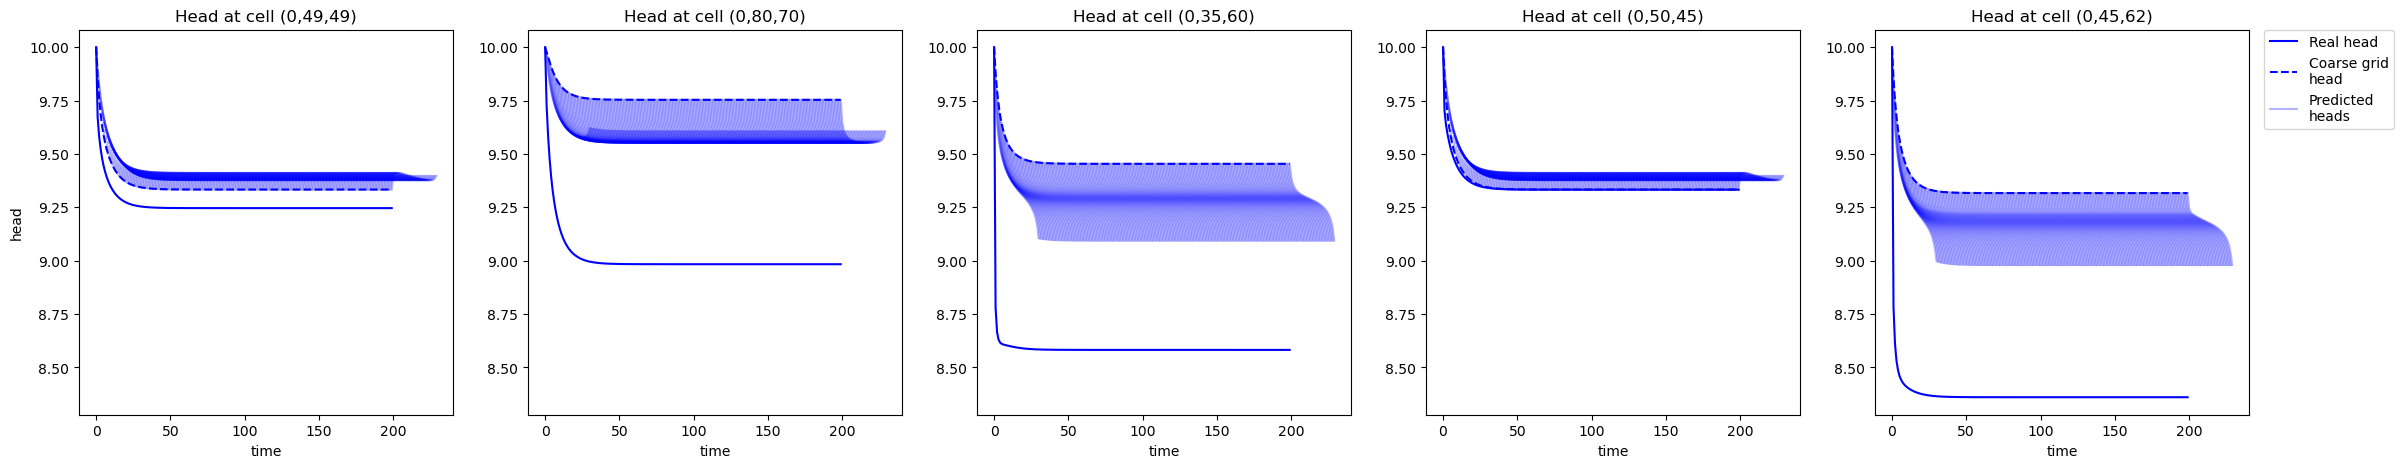

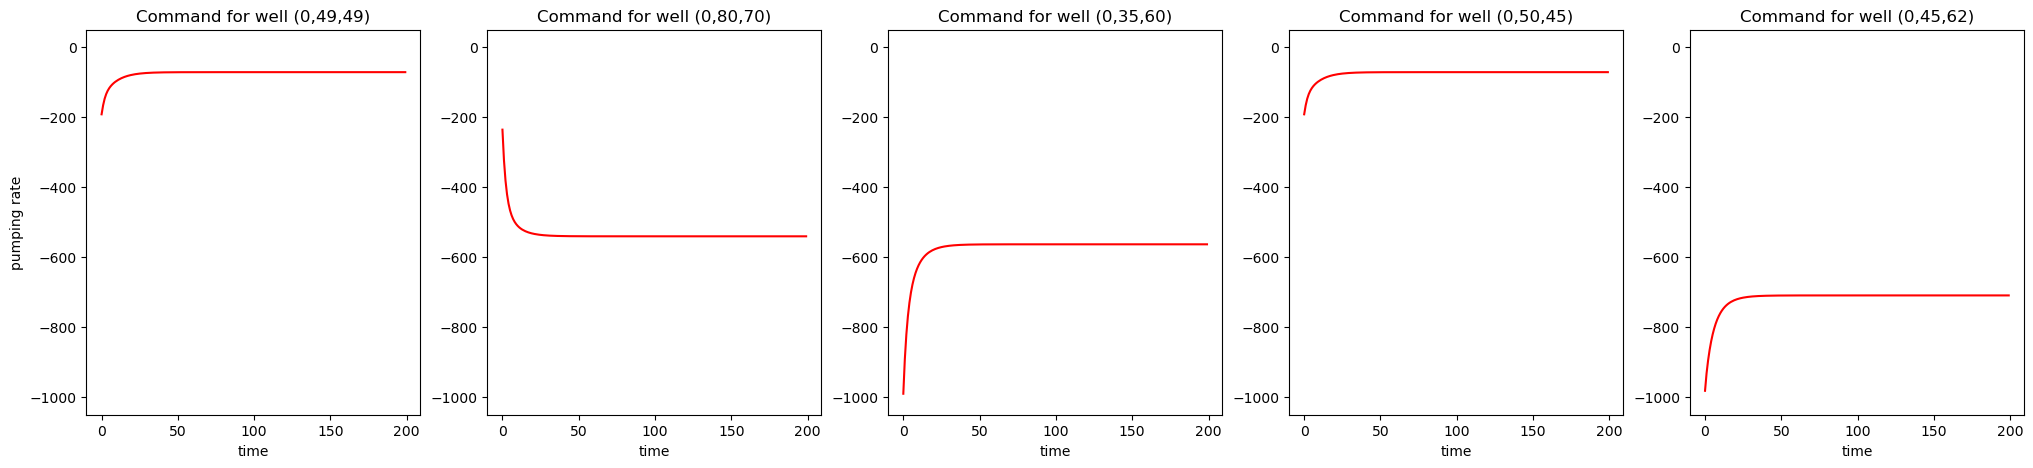

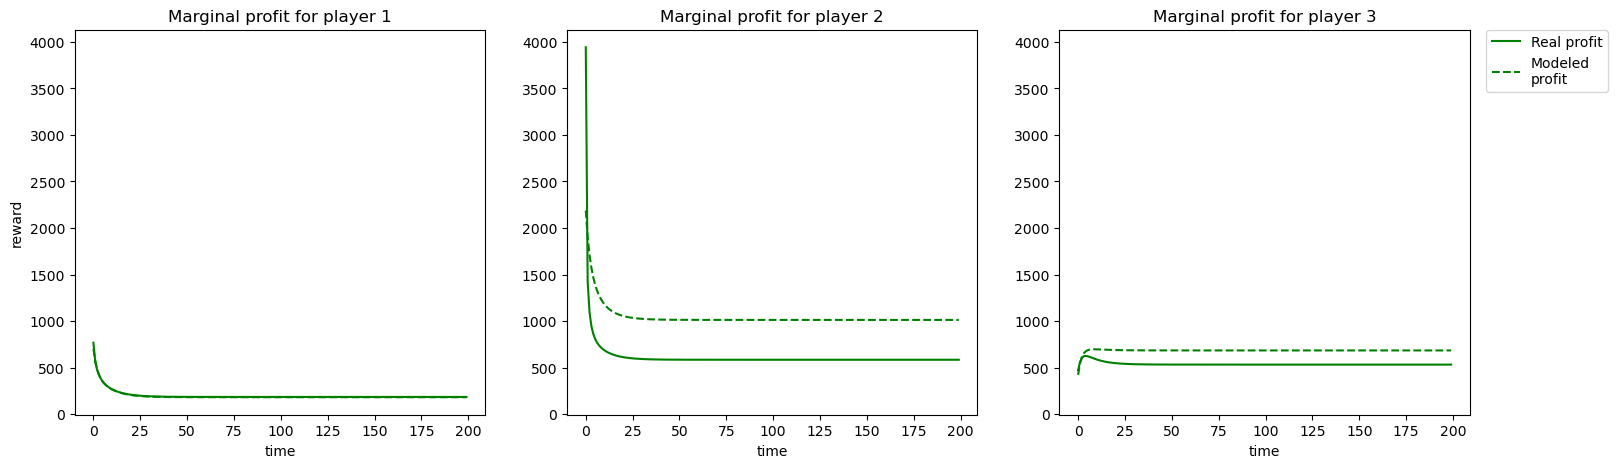

In [ ]:
# Run loop
receding_horizon.run(time_period=200, display_results=True)

In [ ]:
data = np.load("run_data/run_20250528-160218/result_data.npz")

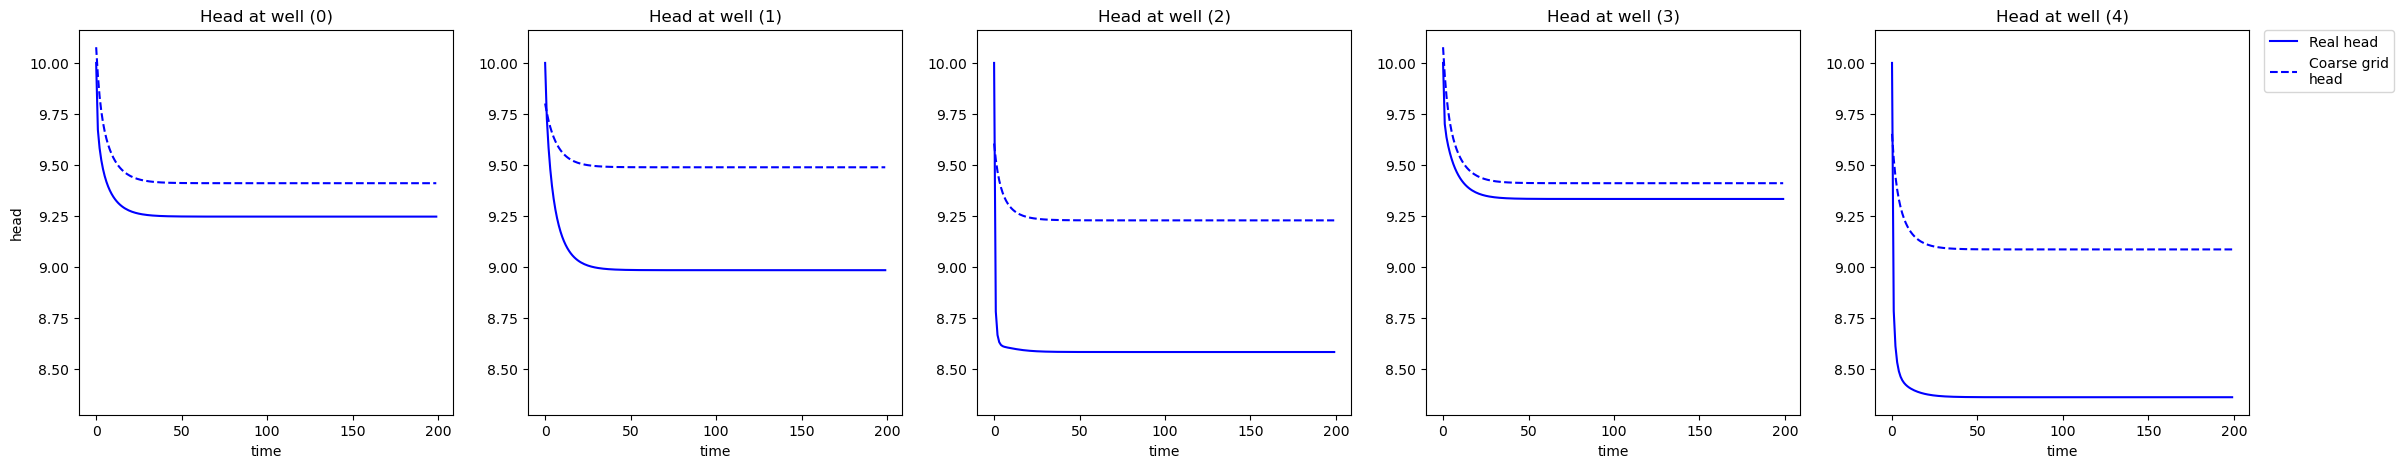

In [ ]:
# Display corrected heads evolution
correction = C_u @ model_copy.input_to_well.T @ data['q_rates']
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data['avg_h_wells'][ii, :] + correction[ii,:], "b--", label="Coarse grid\nhead")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [ ]:
correction[:,-1]

array([ 0.07676041, -0.26530532, -0.22587405,  0.07676041, -0.23133066])

In [ ]:
print(data['h_wells'][:, -1] - data['avg_h_wells'][:, -1])

[-8.70986390e-02 -7.69964330e-01 -8.71498382e-01 -5.42204380e-04 -9.56206598e-01]


In [ ]:
head[:, -1, well_pos[ii], :].flatten()

array([10.        ,  9.98351906,  9.960288  ,  9.93637088,  9.91392393,  9.8934903 ,  9.87506294,  9.8584727 ,  9.8435212 ,  9.83002233,  9.8178129 ,  9.80675239,  9.79671998,  9.7876112 ,  9.77933473,  9.77181039,  9.76496704,  9.75874129,  9.75307614,  9.74792035,  9.7432277 ,  9.73895624,  9.735068  ,  9.73152854,  9.72830647,  9.72537337,  9.72270328,  9.72027265,  9.71806001,  9.71604575,  9.71421219,  9.71254309,  9.71102371,  9.70964064,  9.70838166,  9.70723566,  9.70619244,  9.70524284,  9.70437844,  9.70359161,  9.7028754 ,  9.70222349,  9.70163004,  9.70108988,  9.7005982 ,  9.70015064,  9.69974326,  9.69937242,  9.69903491,  9.69872763,  9.69844797,  9.69819339,  9.6979617 ,  9.69775082,  9.6975588 ,  9.69738407,  9.69722499,  9.69708022,  9.69694843,  9.69682847,  9.69671926,  9.69661988,  9.6965294 ,  9.69644705,  9.69637208,  9.69630384,  9.69624174,  9.69618521,  9.69613378,  9.69608691,  9.69604427,  9.69600548,  9.69597018,  9.69593806,  9.69590878,  9.69588214,  9.69

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_10017/2576841908.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)


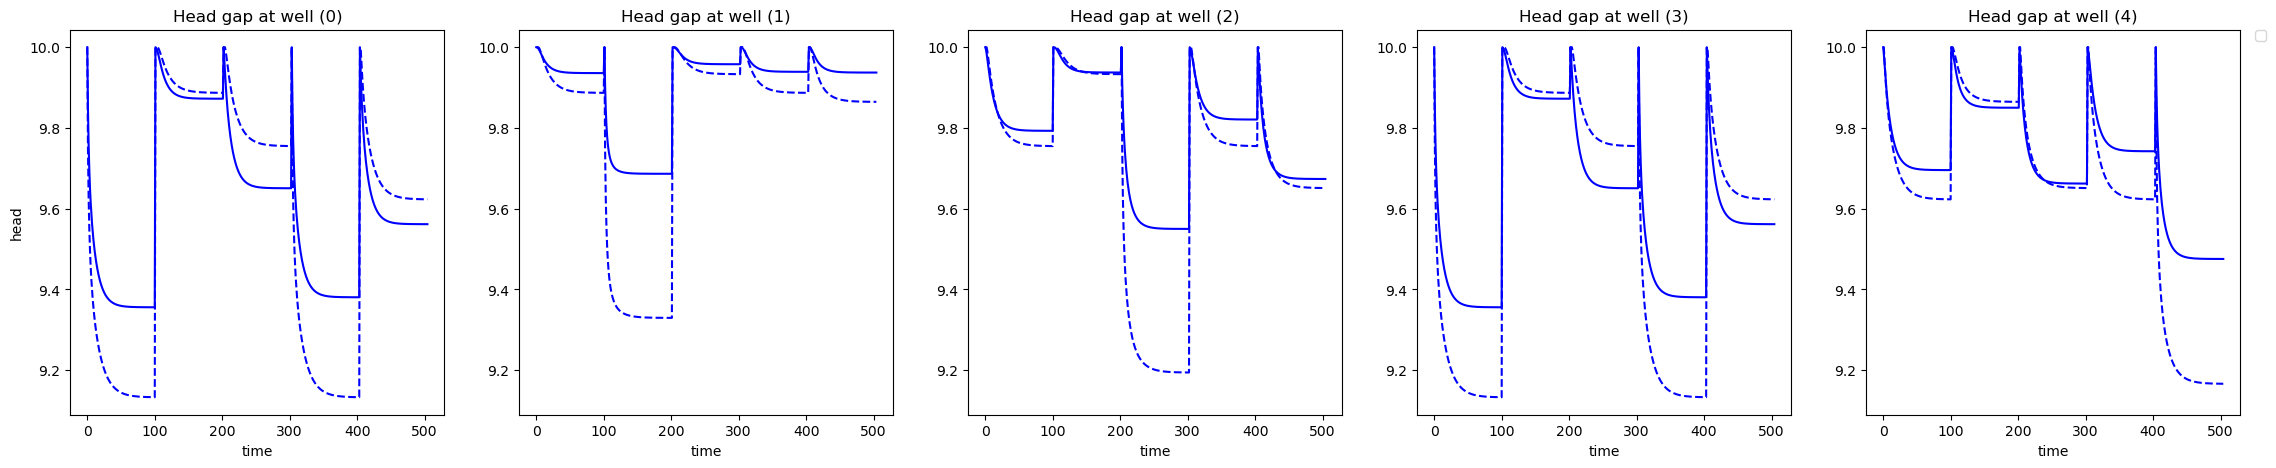

In [ ]:
well_pos = np.nonzero(model.well_to_cell.T)[1]
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(head[:, -1, well_pos[ii], :].flatten(), "b-")
    ax_h.plot(model_head[:, -1, well_pos[ii], :].flatten(), "b--")
        # ax_h.plot( - head[ii, n_i, well_pos[ii], :], color=plt.get_cmap('Blues')((15+n_i)/(n_steps_intensity+17)), label=f"u={int((n_i+1)*intensity_step)}")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [ ]:
C_u @ model_copy.input_to_well.T

array([[ 2.35280400e-04, -1.45491125e-05, -1.04429784e-04,  2.35280400e-04, -6.15001865e-05],
       [ 5.04816233e-05,  3.56954058e-04,  2.46087919e-05,  5.04816233e-05,  7.24945661e-05],
       [ 5.17806975e-05,  4.12682171e-06,  3.55681408e-04,  5.17806975e-05,  2.25303726e-05],
       [ 2.35280400e-04, -1.45491125e-05, -1.04429784e-04,  2.35280400e-04, -6.15001865e-05],
       [ 9.57737508e-05, -1.46237228e-05,  1.12120369e-05,  9.57737508e-05,  3.09215706e-04]])

In [ ]:
data['q_rates'][:,-1]

array([ -71.22953761, -540.26030302, -563.118927  ,  -71.22953761, -709.12867286])

In [ ]:
C_u @ model_copy.input_to_well.T @ np.diag(data['q_rates'][:,-1], k=0)

array([[-0.01675891,  0.00786031,  0.05880639, -0.01675891,  0.04361155],
       [-0.00359578, -0.19284811, -0.01385768, -0.00359578, -0.05140798],
       [-0.00368832, -0.00222956, -0.20029093, -0.00368832, -0.01597693],
       [-0.01675891,  0.00786031,  0.05880639, -0.01675891,  0.04361155],
       [-0.00682192,  0.00790062, -0.00631371, -0.00682192, -0.21927372]])

In [ ]:
model_copy.input_to_well.T @ (1000*base_command[0][:,[0]])

array([[-1000.],
       [    0.],
       [    0.],
       [    0.]])

In [ ]:
C_u @ model_copy.input_to_well.T @ (1000*base_command[1][:,0])

array([ 0.01454911, -0.35695406, -0.00412682,  0.01454911,  0.01462372])

In [ ]:
C_u @ model_copy.input_to_well.T @ (1000*np.ones((5,)))

array([0.29008172, 0.55502066, 0.4859    , 0.29008172, 0.49735152])

The maximum correction is far from the actual gap that we have in well (1)

We probably under estimate the effects of interactions

## Using random inputs as training data

In [15]:
n_sample = 100
train_command = [(np.random.randint(-1000,0, (1,5))*np.ones((T, 5))).T for _ in range(n_sample)]

In [17]:
model.translate_state(system.get_state()[0,:,:]).flatten().shape

(25,)

In [88]:
# Compute heads and costs for different commands at different wells
head_rd = np.array([np.hstack((system.get_heads_at_wells()[:,np.newaxis], np.zeros((n_well, T))))] * n_sample)
cost_rd = np.array([np.zeros((model.n_agent, T))] * n_sample)
for step in trange(n_sample):
    system.state = system.initial_state.copy()
    for k in range(T):
        system.apply_command(train_command[step][:,[k]])
        head_rd[step, :, k+1] = system.get_heads_at_wells()
        cost_rd[step, :, k] = system.compute_cost(train_command[step][:,[k]]).flatten()

100%|██████████| 100/100 [12:59<00:00,  7.79s/it]


In [19]:
# Compute expected heads for those commands
B = sp.hstack(model.B_v)
system.state = system.initial_state.copy()
model_head_rd = np.array([np.hstack((model.translate_state(system.get_state()[0,:,:]), np.zeros((model.nx, T))))] * n_sample)
model_cost_rd = np.array([np.zeros((model.n_agent, T))] * n_sample)
for step in trange(n_sample):
    for k in range(T):
        input = model.input_to_well.T @ train_command[step][:,[k]]
        model.state = model_head_rd[step, :, [k]].T
        model_head_rd[step, :, k+1] = (model.A @ model_head_rd[step, :, [k]].T + B @ input + model.C).flatten()
        model_cost_rd[step, :, k] = model.compute_cost(train_command[step][:,[k]]).flatten()

100%|██████████| 100/100 [00:06<00:00, 15.98it/s]


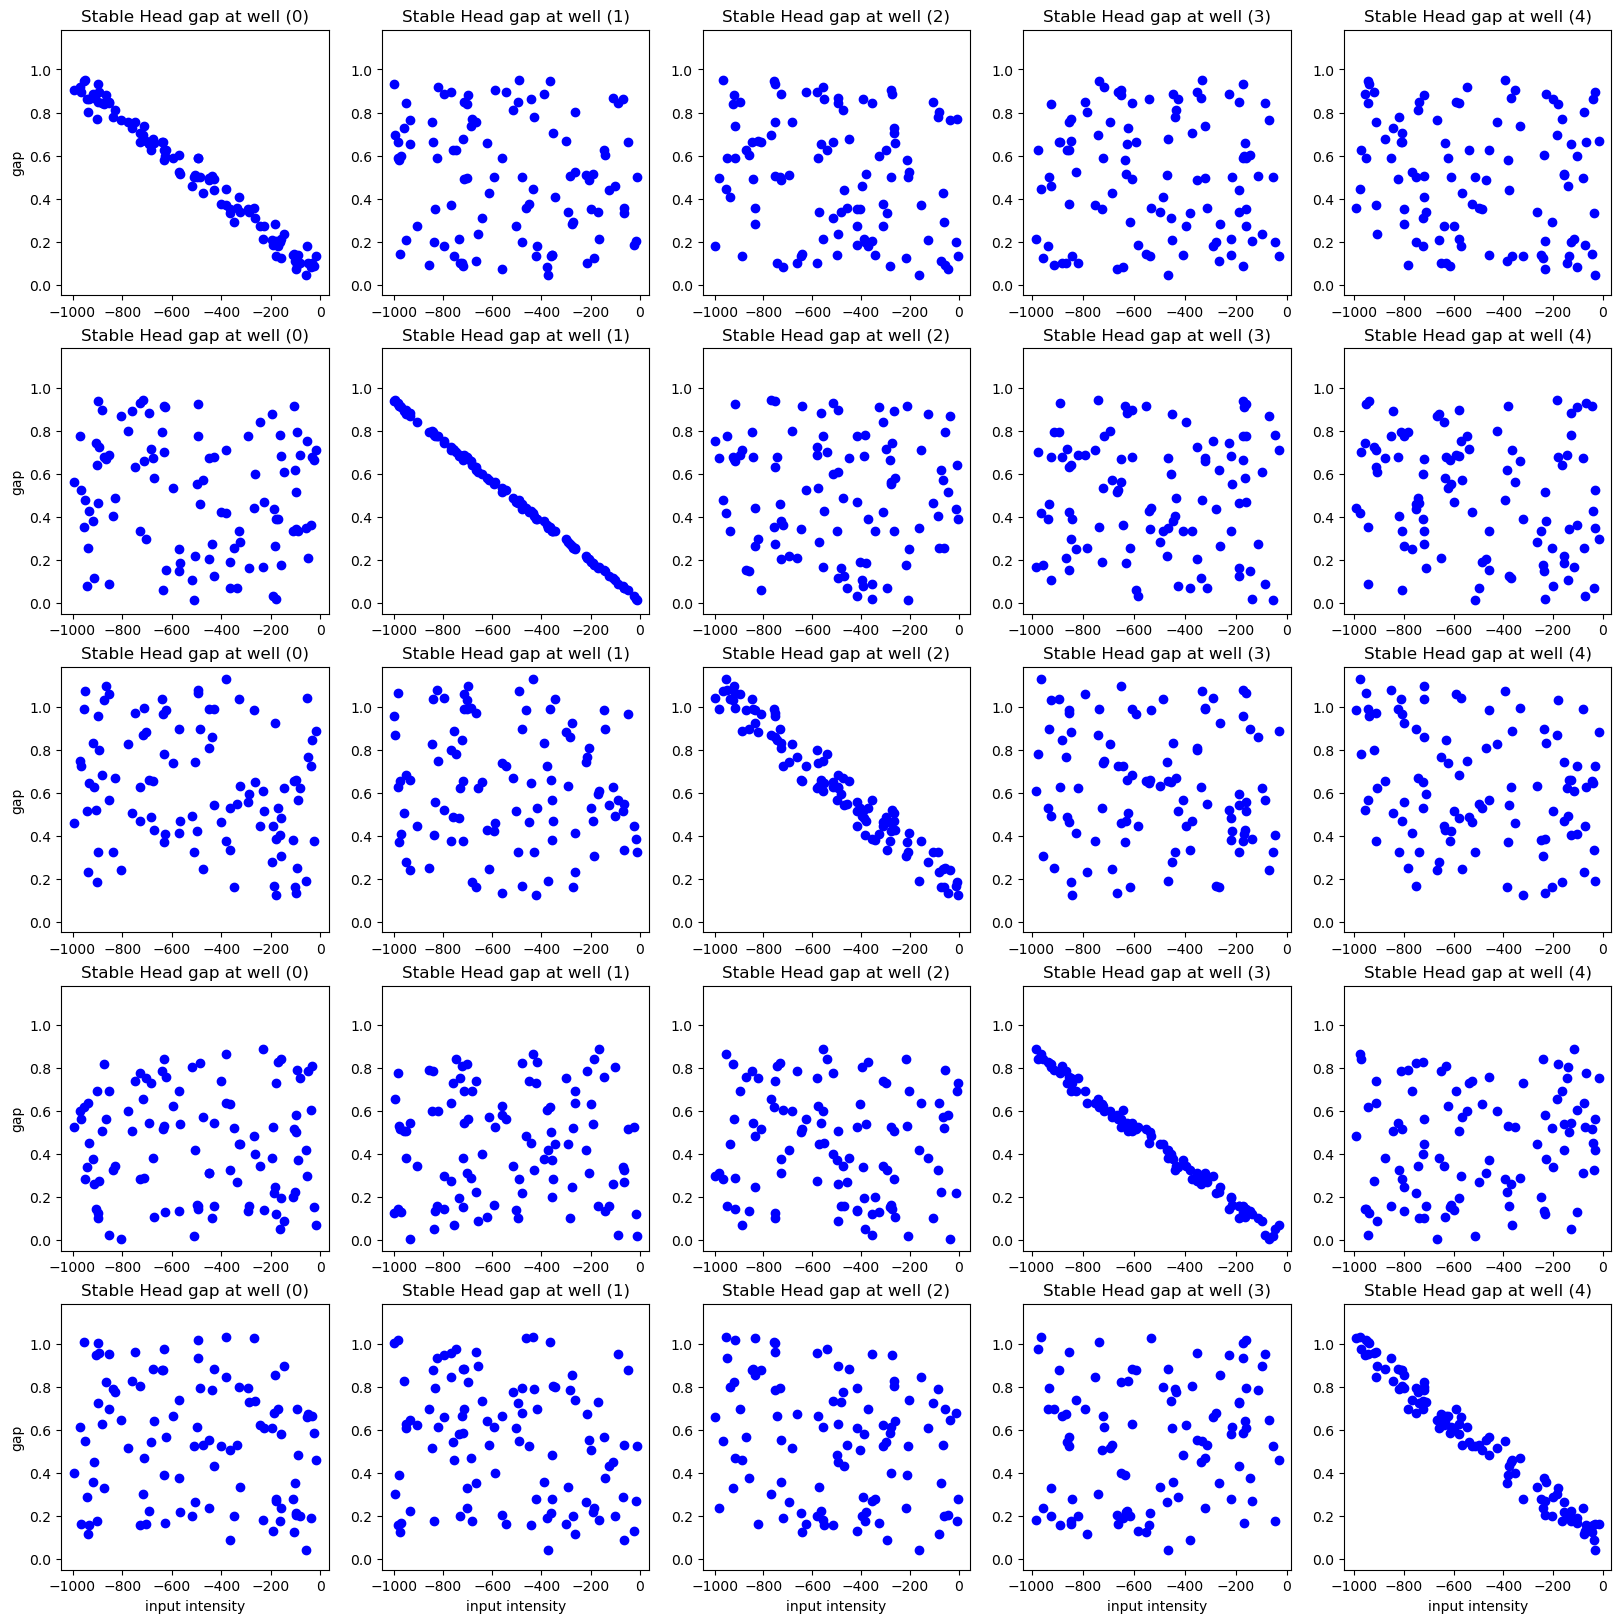

In [102]:
fig_h = plt.figure(figsize=(20,20))
ax_h = None
for ii in range(n_well):
    for jj in range(n_well):
        ax_h = fig_h.add_subplot(5, 5, 5*jj+ii+1, sharey=ax_h)
        ttl = f"Stable Head gap at well ({ii})"
        ax_h.set_title(ttl)
        if jj == n_well-1:
            ax_h.set_xlabel("input intensity")
        if ii == 0:
            ax_h.set_ylabel("gap")
        ax_h.scatter([train_command[_][ii,0] for _ in range(n_sample)], model_head_rd[:, well_pos[jj], -1] - head_rd[:, jj, -1], color="blue", label="data")

The only real corelation seems to be in it's own well.

Fit linear function between pumping at well and error term in the same well.

In [92]:
pumping_rates = np.array([[train_command[_][ii,0] for _ in range(n_sample)] for ii in range(n_well)])
error = np.array([model_head_rd[:, well_pos[ii], -1] - head_rd[:, ii, -1] for ii in range(n_well)])

In [93]:
res = least_squares(lambda x : (x*pumping_rates.flatten() - error.flatten()), x0 = 0)
cx_u = res.x

In [94]:
cx_u

array([-0.00100017])

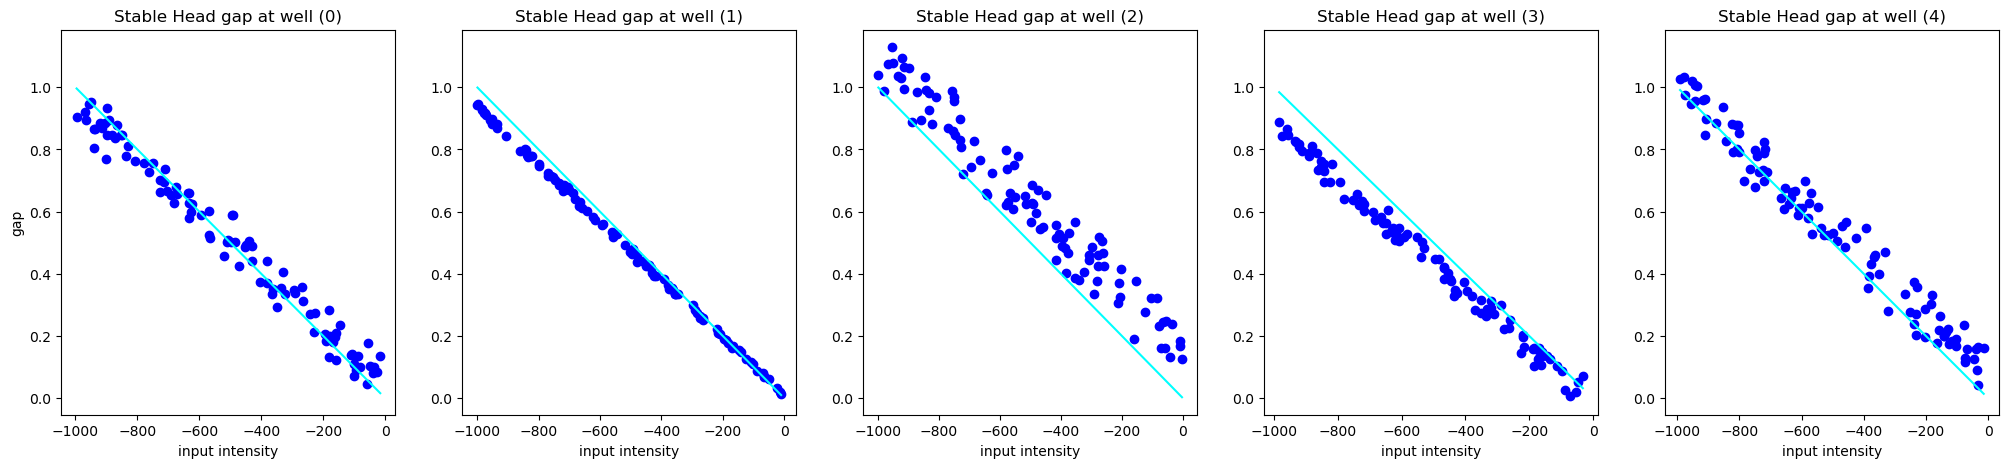

In [101]:
fig_h = plt.figure(figsize=(25,5))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Stable Head gap at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("input intensity")
    if ii == 0:
        ax_h.set_ylabel("gap")
    ax_h.scatter([train_command[_][ii,0] for _ in range(n_sample)], model_head_rd[:, well_pos[ii], -1] - head_rd[:, ii, -1], color="blue", label="data")
    arg_sort = pumping_rates[ii,:].argsort()
    ax_h.plot(pumping_rates[ii,arg_sort], cx_u * pumping_rates[ii,arg_sort], color="cyan")

In [107]:
model.input_to_well[:, :].sum(axis=0)

array([2., 1., 1., 1.])

# Result: head constraint

In [3]:
data = np.load("run_data/run_20250603-114029/result_data.npz")

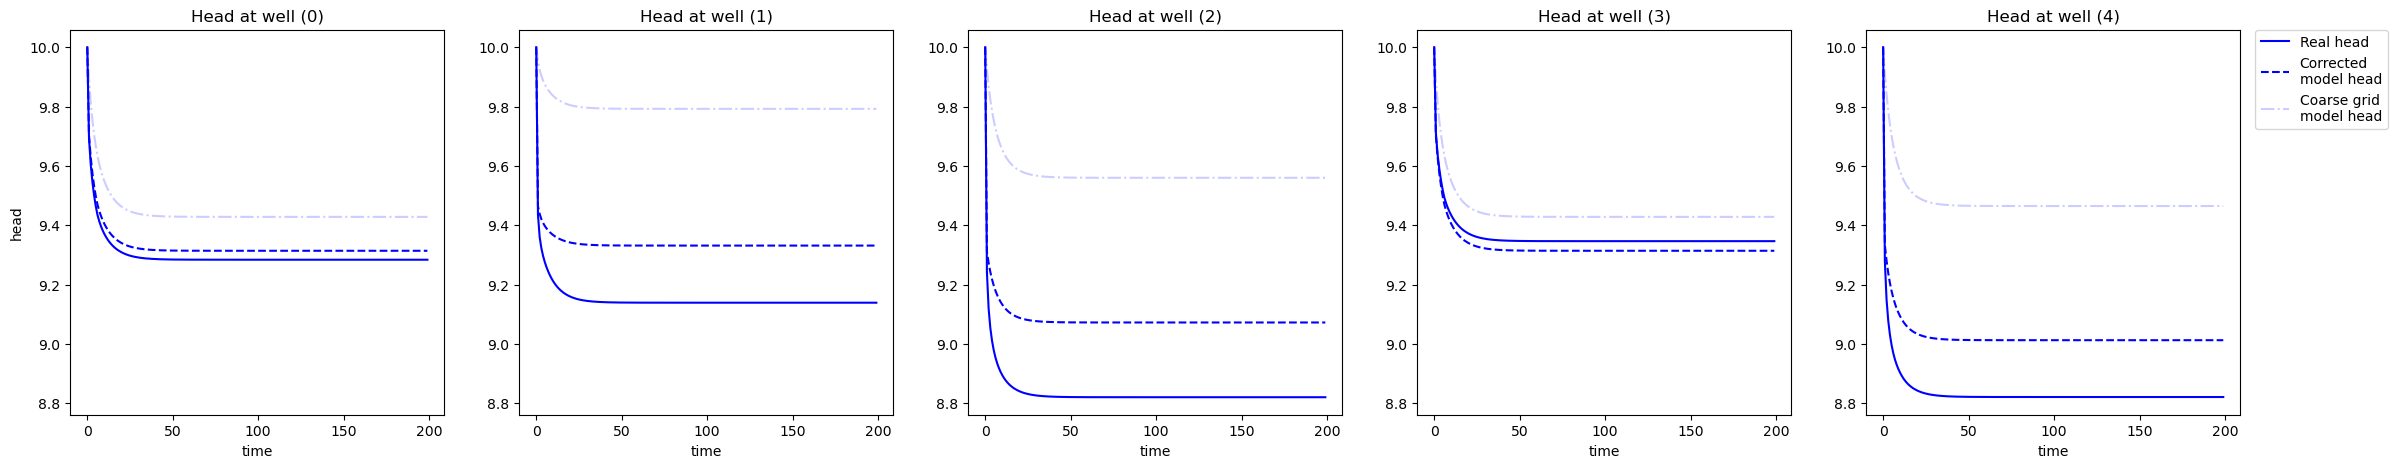

In [6]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data['corrected_h_wells'][ii, :], "b--", label="Corrected\nmodel head")
    ax_h.plot(data['avg_h_wells'][ii, :], "b-.", alpha=0.2, label="Coarse grid\nmodel head")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
# # Display command evolution
# fig_q = plt.figure(figsize=(25,5))
# ax_q = None
# for ii in range(5):
#     ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
#     ttl = f"Command for well ({well_coord[ii, 0]},{well_coord[ii, 1]},{well_coord[ii, 2]})"
#     ax_q.set_title(ttl)
#     ax_q.set_xlabel("time")
#     if ii == 0:
#         ax_q.set_ylabel("pumping rate")
#     ax_q.plot(self.q_rates[ii, :], "r-")
#     ax_q.set_ylim([-1050, 50])
# # Display profit evolution
# fig_p = plt.figure(figsize=(15+3,5))
# ax_p = None
# for ii in range(3):
#     ax_p = fig_p.add_subplot(1, 3, ii+1, sharey=ax_p)
#     ttl = f"Marginal profit for player {ii+1}"
#     ax_p.set_title(ttl)
#     ax_p.set_xlabel("time")
#     if ii == 0:
#         ax_p.set_ylabel("reward")
#     ax_p.plot(self.real_profits[ii, :], "g-", label="Real profit")
#     ax_p.plot(self.model_profits[ii, :], "g--", label="Modeled\nprofit")
# ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
# # Show figures
# fig_h.show()
# fig_q.show()
# fig_p.show()